# Lab 3 — Chan–Vese Segmentation

*Optimization Techniques for Computer Vision*

**Segmentation** splits an image into meaningful regions. The **Chan–Vese** model ("active contours without edges") does not look for edges at all: it looks for the boundary $C$ that best splits the image into **two regions**, each well described by a simple model, while keeping $C$ short. It is a simplified **Mumford–Shah** functional, minimized with a **level set** representation of $C$.

In this lab you will:

1. solve a **1D** two-phase Mumford–Shah problem **exactly**, by dynamic programming (the Viterbi algorithm);
2. write the Chan–Vese energy with **level sets**, and check how the regularized Heaviside and Dirac functions measure length;
3. minimize it with an **explicit** and a **semi-implicit** gradient descent;
4. segment noisy phantoms, compare with **thresholding**, and study the effect of the length weight $\mu$;
5. segment regions that differ only in their **variance**, by understanding what $\lambda_1$, $\lambda_2$ and $\nu$ really mean (a statistical interpretation of Chan–Vese);
6. segment **color** images (Chan–Sandberg–Vese) and an image of your choice;
7. *(bonus)* compute a **global minimizer** by convex relaxation and a primal–dual algorithm.

The reference for the model and its numerical scheme is: P. Getreuer, "Chan–Vese Segmentation", *Image Processing On Line* 2 (2012), pp. 214–224, [doi:10.5201/ipol.2012.g-cv](https://doi.org/10.5201/ipol.2012.g-cv). Equation numbers "(G.xx)" below refer to that paper.

### How to work

* **Cell legend**
    * 📘 **blue banner**: theory. Read it; the questions build on it.
    * 🟨 **yellow banner / `# 🟨 YOUR CODE HERE`**: code you must complete (replace the `raise NotImplementedError`).
    * 🟩 **green banner / `# 🟩 ANSWER CELL`**: a question, followed by the cell where you give your answer with `answer("Qx.y", ...)`. Executing it shows your answer in a **green box**.
* Many numerical answers are computed by the provided code once your implementation is correct. For multiple-choice questions, write the letter and a short justification.
* Follow the specifications in the comments, so that your numbers can be compared with the reference.
* Running the whole notebook takes a few minutes: most experiments run hundreds of iterations on $256\times256$ images.

### Grading

The lab is graded on **10 points**; each question shows its points in its green banner. The optional bonus exercise is worth **1 extra point**. A table with all questions and points is at the end of the notebook.

### Hand-in

1. `Runtime → Restart session and run all`, and check that **no cell fails** (except the optional bonus, if you did not attempt it).
2. Check that every green answer box shows your answer.
3. `File → Download → Download .ipynb`, and upload that file **with all outputs**.

### Contents
0. Setup
1. Warm-up: two-phase segmentation of a 1D signal
2. From Mumford–Shah to Chan–Vese: the level-set energy
3. Gradient descent: explicit and semi-implicit schemes
4. Regions with different means
5. Regions with equal means and different variances
6. Color images and your own image
* Bonus: a global minimizer by convex relaxation
* Grading table

---
## 0. Setup

In [2]:
# Only the standard scientific stack (all preinstalled on Colab)
import base64, io, time

import numpy as np
import scipy.ndimage as ndi               # connected components, filtering
from skimage import data
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import HTML, display

plt.rcParams["figure.dpi"] = 90
np.set_printoptions(precision=4, suppress=True)

**Random seeds.** All noise in this notebook is generated with NumPy's pseudo-random number generator. The **seed** fixes its initial state: the same seed always produces the same "random" numbers, so the notebook is **reproducible** and your results can be compared with the reference. Each experiment has its own seed, defined below.

In [3]:
SEED_1D = 1         # Part 1: 1D signal
SEED_MEAN = 2       # Parts 2-4: phantom with different means
SEED_DISKS = 3      # Part 4: clusters of disks
SEED_VAR = 4        # Part 5: phantom with different variances
SEED_COLOR = 5      # Part 6: color phantom

In [4]:
# ---------------------------------------------------------------
# Answer display: shows an answer in a green box (orange if still missing)
# ---------------------------------------------------------------
def answer(qid, value):
    if value is None or (isinstance(value, str) and value.strip() in ("", "?")):
        style = "background:#fef7e0;border-left:6px solid #f9ab00;color:#7a4f01"
        text = "⚠️ not answered yet"
    else:
        style = "background:#e6f4ea;border-left:6px solid #34a853;color:#1e4620"
        text = f"{value:.5g}" if isinstance(value, (float, np.floating)) else str(value)
    display(HTML(f'<div style="{style};padding:6px 10px;font-family:monospace;font-size:14px">'
                 f'🟩 <b>{qid}</b>: {text}</div>'))

# ---------------------------------------------------------------
# Display helpers
# ---------------------------------------------------------------
def show(images, titles=None, size=3.3, contours=None, color="r"):
    # Show images side by side (grayscale in [0, 1] or RGB); optionally overlay the zero level set of phi's
    images = list(images)
    fig, axes = plt.subplots(1, len(images), figsize=(size * len(images), size))
    for k, (ax, im) in enumerate(zip(np.atleast_1d(axes), images)):
        if im.ndim == 2:
            ax.imshow(im, cmap="gray", vmin=0, vmax=1)
        else:
            ax.imshow(np.clip(im, 0, 1))
        if contours is not None and contours[k] is not None:
            ax.contour(contours[k], levels=[0], colors=color, linewidths=1.2)
        ax.set_axis_off()
        if titles is not None:
            ax.set_title(titles[k], fontsize=9)
    plt.tight_layout()
    plt.show()

def accuracy(seg, truth):
    # Fraction of correctly labelled pixels. Chan-Vese with nu = 0 does not know which region is "inside",
    # so we accept either labelling.
    a = float(np.mean(seg == truth))
    return max(a, 1.0 - a)

### Test images

All 2D test images are generated from **one** embedded black-and-white image: the region mask of the legacy `phantom1.bmp` ($256\times256$, about half of the pixels white). The cell below decodes it; `make_phantom` then paints the two regions with random noise of prescribed statistics. This way each experiment states exactly what distinguishes the two regions.

In [5]:
# Embedded image data (do not edit): phantom1 region mask, 1-bit PNG, base64-encoded
PHANTOM1_PNG_B64 = (
    "iVBORw0KGgoAAAANSUhEUgAAAQAAAAEAAQAAAAB0CZXLAAACKElEQVR42t2ZS27jMBAF1QyB4ZJH4FF4tD6aj+IjZHYJMDOcTRz9"
    "SJeBBxpGvItSqNfdlGyJWpYf8XH4f1imA8vlBWq4vkAN7/MjPuZH/Jkf8U82tCcst8uGOr/IIhuybEiyIcqGIBtMXywnoMoRRTZk"
    "2ZAIiHJEIMD0K8sJqHJEISDLEYmASECQazA0OAGVgCJ/kWYCEgGRgECAYRdOQCWgEJAJSAREAgIBhqvpBFQC7gyitdZa+yBDJCAQ"
    "YHjSOhTZrmTIBAzX077uo1oAg+GldyGgQJvD1fg2ROhiWGagR5UVKBTxmQAYzHI9an5/DqMVXyMGRWyAfhGbg3aBGto7RPQztsf6"
    "jTbI2EZ0M3aHen3sDMvfCL8Xbw6GzrgPZf26gOHcyPFvu4LhdHYHegA9Gw5VnA2HKs6Gwyw6wL7MQM/qPcNuyXrALiPQfkDXsO2j"
    "C2xn1Y3Ynd6t97lCxLaI/rdGJMNmEoF2ZwaG3xkMiQzrqAYGLHKtcgQUqGGd5cgQyfBd5vBX3QmoBBQCMhV5uzgC/SQPAWzz1ucY"
    "qFDk7aQaGxJFUJt8C2b4dOAEVAKKvJNDg/qa1B0gPnbLfQcw7MIJqPKOViEgE5AIiA89pEldGBpcjVgqAUWOyAQkOSI+svegRRga"
    "XN6GrbKhyIZMQJIjomwIssH0PXOXDVU2lPlvo7JsSLIhzm8zzI8wPcLnv3ysT3i/SUCZH5HnR6QXmGR8Qg3/ASvxpEzwRcLnAAAA"
    "AElFTkSuQmCC"
)

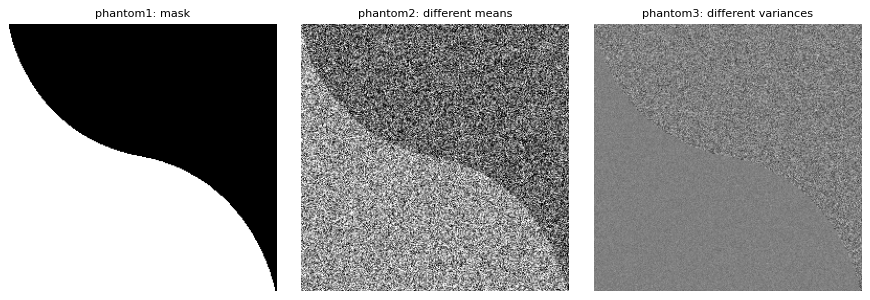

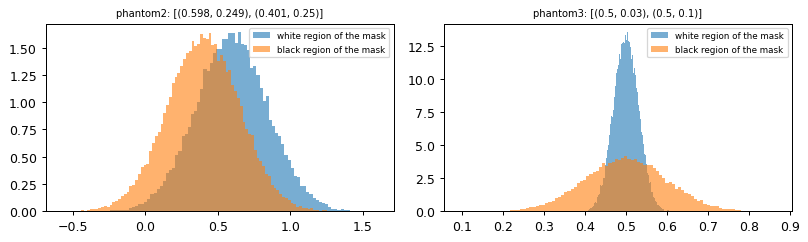

In [6]:
MASK = np.asarray(Image.open(io.BytesIO(base64.b64decode(PHANTOM1_PNG_B64))).convert("L")) > 127   # True = white region

def make_phantom(mask, mean_in, mean_out, std_in, std_out, rng):
    # Gaussian noise with mean/std (mean_in, std_in) on the mask and (mean_out, std_out) elsewhere
    f = np.where(mask, mean_in, mean_out).astype(float)
    return f + np.where(mask, std_in, std_out) * rng.standard_normal(mask.shape)

def region_stats(f, mask):
    # (mean, std) of f on the mask and on its complement
    return [(round(float(f[r].mean()), 3), round(float(f[r].std()), 3)) for r in (mask, ~mask)]

phantom1 = MASK.astype(float)
phantom2 = make_phantom(MASK, 0.6, 0.4, 0.25, 0.25, np.random.default_rng(SEED_MEAN))    # different means, heavy noise
phantom3 = make_phantom(MASK, 0.5, 0.5, 0.03, 0.10, np.random.default_rng(SEED_VAR))     # equal means, different stds

show([phantom1, phantom2, phantom3], ["phantom1: mask", "phantom2: different means", "phantom3: different variances"])
fig, ax = plt.subplots(1, 2, figsize=(9, 2.8))
for a, f, name in zip(ax, [phantom2, phantom3], ["phantom2", "phantom3"]):
    a.hist(f[MASK], 100, alpha=0.6, density=True, label="white region of the mask")
    a.hist(f[~MASK], 100, alpha=0.6, density=True, label="black region of the mask")
    a.set_title(f"{name}: {region_stats(f, MASK)}", fontsize=8); a.legend(fontsize=7)
plt.tight_layout(); plt.show()

---
## 1. Warm-up: two-phase segmentation of a 1D signal

<div style="background-color:#e8f0fe; border-left:6px solid #4285f4; padding:6px 12px; font-weight:bold; color:#174ea6;">📘 1.1 Mumford–Shah in 1D, and counting jumps</div>

The **Mumford–Shah** functional approximates an image $f$ by a piecewise-smooth function $u$ with a discontinuity set $J$:

$$
E_{MS}(u,J) = \mu\,\mathcal{H}^{d-1}(J) + \lambda\int_\Omega (f-u)^2\,dx + \int_{\Omega\setminus J}\|\nabla u\|^2\,dx .
$$

* The last term asks $u$ to be smooth **away from** $J$, and the second term keeps $u$ close to $f$.
* $\mathcal{H}^{d-1}(J)$ is the $(d-1)$-dimensional **Hausdorff measure** of $J$: the "size" of the discontinuity set, measured in the dimension it naturally has. In a 2D image ($d=2$), $J$ is a set of curves and $\mathcal{H}^1(J)$ is their **length**. In a 1D signal ($d=1$), $J$ is a set of points and $\mathcal{H}^0(J)$ is the **number of points**: the counting measure.

**Piecewise-constant, two-phase version.** If $u$ is constant between jumps, the gradient term vanishes. If moreover $u$ may only take **two** values $c_1$ and $c_2$, we obtain the 1D **Chan–Vese** problem. For a sampled signal $f_1,\dots,f_N$, dividing by $\lambda$:

$$
\min_{c_1,c_2,\ \ell\in\{0,1\}^N}\; \sum_{k=1}^{N} \big(f_k - c_{\ell_k}\big)^2 \;+\; \gamma\,\#\{k : \ell_k\neq\ell_{k+1}\},\qquad \gamma=\mu/\lambda ,
$$

where the label $\ell_k\in\{1,2\}$ says which value pixel $k$ takes (we write it as $0/1$ in the code). The second term counts the jumps: it is $\mathcal{H}^0(J)$.

**The role of $\gamma$.** A pair of jumps (an isolated "segment" of length $L$ inside the other phase) costs $2\gamma$. It is worth paying only if it reduces the data term by more than $2\gamma$. A segment of length $L$ whose values differ by $\Delta=|c_1-c_2|$ from its surroundings reduces the data term by about $L\Delta^2$: short segments (noise) disappear when $\gamma$ grows; long ones survive.

<div style="background-color:#e8f0fe; border-left:6px solid #4285f4; padding:6px 12px; font-weight:bold; color:#174ea6;">📘 1.2 Exact minimization by dynamic programming (Viterbi)</div>

For **fixed** $c_1,c_2$, the problem over the labels has a chain structure: the cost couples only neighboring labels. Let $D_k(s)$ be the smallest cost of labelling $f_1,\dots,f_k$ with $\ell_k=s$. Then (Bellman's principle of optimality)

$$
D_1(s) = (f_1-c_s)^2,\qquad
D_k(s) = (f_k-c_s)^2 + \min\big\{\,D_{k-1}(s),\; D_{k-1}(1-s)+\gamma\,\big\} .
$$

Keep track of which option was chosen (a "back-pointer" $b_k(s)$). The minimum energy is $\min_s D_N(s)$, and the optimal labels are recovered **backwards**: $\ell_N = \arg\min_s D_N(s)$, then $\ell_{k-1} = b_k(\ell_k)$. This is the **Viterbi algorithm**, the same one used to decode convolutional codes or hidden Markov models. It costs $O(N)$ and returns the **global** minimizer over all $2^N$ labelings.

**Alternating minimization.** We then alternate:
1. labels $\leftarrow$ Viterbi, for the current $c_1,c_2$;
2. $c_1,c_2 \leftarrow$ averages of $f$ over the pixels with label 1 and label 2 (the minimizers of the data term for fixed labels).

Each step can only decrease the energy, and there are finitely many labelings, so the alternation stops after a few rounds. The result is a **local** minimizer of the joint problem: the energy is not convex in $(c_1,c_2,\ell)$ together.

**Why not in 2D?** On a 2D pixel grid, every pixel has four neighbors and the graph has loops: there is no chain ordering, and the dynamic program does not apply. This is why we will use level sets and gradient descent (or, in the bonus, a convex relaxation).

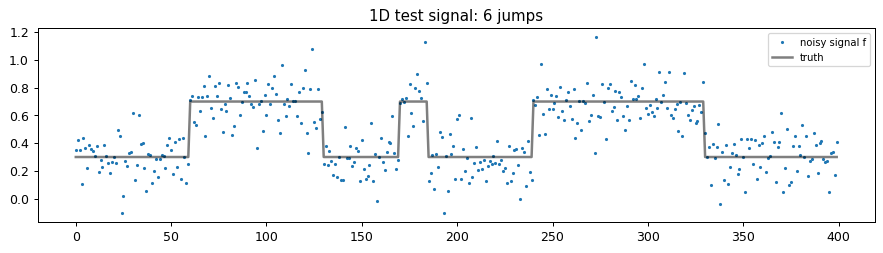

In [7]:
# A noisy 1D signal with two levels and 6 jumps (think of one row of an image)
rng1 = np.random.default_rng(SEED_1D)
N1 = 400
truth1 = np.zeros(N1, dtype=bool)
for a, b in [(60, 130), (170, 185), (240, 330)]:
    truth1[a:b] = True
signal = np.where(truth1, 0.7, 0.3) + 0.15 * rng1.standard_normal(N1)

plt.figure(figsize=(12, 2.8))
plt.plot(signal, ".", ms=3, label="noisy signal f"); plt.plot(np.where(truth1, 0.7, 0.3), "k", lw=2, alpha=0.5, label="truth")
plt.legend(fontsize=8); plt.title("1D test signal: 6 jumps"); plt.show()

<div style="background-color:#fef7e0; border-left:6px solid #f9ab00; padding:6px 12px; font-weight:bold; color:#7a4f01;">🟨 TODO 1 — the Viterbi algorithm for two phases</div>

Implement `viterbi_two_phase(f, c1, c2, gamma)` following Section 1.2. Label `True` means value `c1`, `False` means value `c2`. A loop over $k$ is fine ($N=400$).

In [8]:
def viterbi_two_phase(f, c1, c2, gamma):
    # Exact minimizer over labels of  sum_k (f_k - c_{l_k})^2 + gamma * #jumps,  for fixed c1, c2.
    # Returns (labels, energy): labels is a boolean array (True -> c1), energy the minimum value.
    N = len(f)
    cost = np.stack([(f - c2) ** 2, (f - c1) ** 2], axis=1)     # column 0: label False (c2), column 1: label True (c1)
    D = np.zeros((N, 2))
    back = np.zeros((N, 2), dtype=int)
    # 🟨 YOUR CODE HERE
    D[0] = cost[0] # both costs
    for k in range(1, N):
        for s in (0, 1):
            stay = D[k - 1, s]
            switch = D[k - 1, 1 - s] + gamma
            if stay <= switch:
                D[k, s] = cost[k, s] + stay
                back[k, s] = s
            else:
                D[k, s] = cost[k, s] + switch
                back[k, s] = 1 - s
    labels = np.zeros(N, dtype=int)
    labels[-1] = np.argmin(D[-1]) # final costs
    for k in range(N - 1, 0, -1):
        labels[k - 1] = back[k, labels[k]]
        
    return labels.astype(bool), float(D[-1].min())

def two_phase_1d(f, gamma, c1=None, c2=None, max_rounds=100):
    # Alternate Viterbi (labels) and averages (c1, c2). Starts from c1 = max(f), c2 = min(f).
    c1 = f.max() if c1 is None else c1
    c2 = f.min() if c2 is None else c2
    for rounds in range(1, max_rounds + 1):
        labels, E = viterbi_two_phase(f, c1, c2, gamma)
        n1 = f[labels].mean() if labels.any() else c1
        n2 = f[~labels].mean() if (~labels).any() else c2
        if abs(n1 - c1) + abs(n2 - c2) < 1e-12:
            break
        c1, c2 = n1, n2
    return labels, c1, c2, E, rounds

def n_jumps(labels):
    return int(np.sum(labels[1:] != labels[:-1]))

# Check on a tiny example: with a large gamma, the isolated sample is absorbed
print(viterbi_two_phase(np.array([0., 0, 1, 0, 0]), 1.0, 0.0, gamma=0.1)[0],
      viterbi_two_phase(np.array([0., 0, 1, 0, 0]), 1.0, 0.0, gamma=1.0)[0])

[False False  True False False] [False False False False False]


In [9]:
# gamma = 0: no length penalty
lab0, c1_0, c2_0, E0, r0 = two_phase_1d(signal, 0.0)
thresholded = signal > (c1_0 + c2_0) / 2
mismatch0 = int(np.sum(lab0 != thresholded))
print(f"gamma = 0: {n_jumps(lab0)} jumps, c1 = {c1_0:.3f}, c2 = {c2_0:.3f}, {r0} rounds;  "
      f"pixels differing from thresholding at (c1+c2)/2: {mismatch0}")

gamma = 0: 62 jumps, c1 = 0.701, c2 = 0.284, 6 rounds;  pixels differing from thresholding at (c1+c2)/2: 0


<div style="background-color:#e6f4ea; border-left:6px solid #34a853; padding:6px 12px; font-weight:bold; color:#1e4620;">🟩 Question Q1.1 (0.5 points) — answer in the green cell below</div>

**Q1.1** *(0.5 points).* Report the number of jumps found with $\gamma=0$ and the number of pixels where the result differs from thresholding $f$ at $(c_1+c_2)/2$. Explain in one or two sentences why the two coincide, and which classical clustering algorithm the alternation becomes when $\gamma=0$.

In [10]:
# 🟩🟩🟩 ANSWER CELL — Q1.1 🟩🟩🟩
answer("Q1.1", f"{n_jumps(lab0)} jumps, {mismatch0} differing pixels. With gamma = 0 the jump term vanishes, so the label of each sample no longer depends on its neighbours. Each sample simply takes the closer of c1 and c2, which is exactly a threshold at (c1+c2)/2. Is in this case when the alternation behaviour (assign each sample to the closer level, then update c1 and c2 as the means of their groups) is the same as k-means with k=2.")

gamma =  0.00:  62 jumps,  30 wrong samples, c1 = 0.701, c2 = 0.284
gamma =  0.02:  32 jumps,  15 wrong samples, c1 = 0.691, c2 = 0.279
gamma =  0.05:  18 jumps,   8 wrong samples, c1 = 0.692, c2 = 0.285
gamma =  0.10:   6 jumps,   0 wrong samples, c1 = 0.686, c2 = 0.289
gamma =  0.20:   6 jumps,   0 wrong samples, c1 = 0.686, c2 = 0.289
gamma =  0.50:   6 jumps,   0 wrong samples, c1 = 0.686, c2 = 0.289
gamma =  1.00:   6 jumps,   0 wrong samples, c1 = 0.686, c2 = 0.289
gamma =  2.00:   4 jumps,  15 wrong samples, c1 = 0.682, c2 = 0.316
gamma =  5.00:   0 jumps, 175 wrong samples, c1 = 0.678, c2 = 0.463


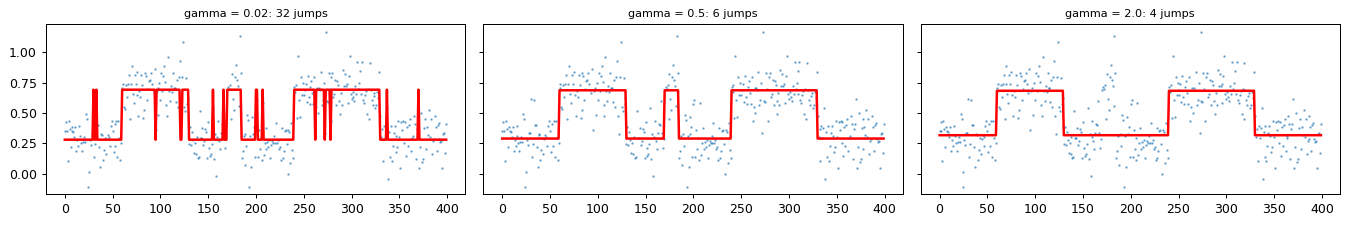

In [11]:
gammas = [0.0, 0.02, 0.05, 0.1, 0.2, 0.5, 1.0, 2.0, 5.0]
sweep1 = []
for g in gammas:
    lab, c1, c2, E, rounds = two_phase_1d(signal, g)
    sweep1.append((g, n_jumps(lab), int(np.sum(lab != truth1)), c1, c2))
    print(f"gamma = {g:5.2f}: {n_jumps(lab):3d} jumps, {sweep1[-1][2]:3d} wrong samples, c1 = {c1:.3f}, c2 = {c2:.3f}")

fig, ax = plt.subplots(1, 3, figsize=(15, 2.6), sharey=True)
for a, g in zip(ax, [0.02, 0.5, 2.0]):
    lab, c1, c2, *_ = two_phase_1d(signal, g)
    a.plot(signal, ".", ms=2, alpha=0.5); a.plot(np.where(lab, c1, c2), "r", lw=2)
    a.set_title(f"gamma = {g}: {n_jumps(lab)} jumps", fontsize=9)
plt.tight_layout(); plt.show()

<div style="background-color:#e6f4ea; border-left:6px solid #34a853; padding:6px 12px; font-weight:bold; color:#1e4620;">🟩 Question Q1.2 (0.5 points) — answer in the green cell below</div>

**Q1.2** *(0.5 points).* From the sweep: for which values of $\gamma$ in the list is the true number of jumps (6) recovered with no wrong sample? Using Section 1.1, explain (i) why small $\gamma$ produces many jumps and (ii) why the short segment $[170,185)$ disappears for large $\gamma$: estimate the value of $\gamma$ above which it is no longer worth keeping (its length is 15 samples and $|c_1-c_2|\approx 0.4$).

In [12]:
# 🟩🟩🟩 ANSWER CELL — Q1.2 🟩🟩🟩
answer("Q1.2", "gamma = 0.1, 0.2, 0.5 and 1.0 recover exactly the 6 jumps with 0 wrong samples.  (i) For small gamma a jump is almost free, so any noisy sample that falls on the wrong side of the midpoint is flipped, since an isolated flip costs only 2*gamma (two jumps), which is almost always the case when gamma is small. (ii) Keeping the segment [170,185) costs 2*gamma (two jumps) and reduces the data term by about L*Delta^2 = 15 * 0.4^2 = 2.4, so it is worth keeping only if 2*gamma < 2.4 (above this value it is absorbed).")

<div style="background-color:#e8f0fe; border-left:6px solid #4285f4; padding:6px 12px; font-weight:bold; color:#174ea6;">📘 1.3 Counting jumps with a level set function</div>

In 2D we will not store the labels directly. Instead, the boundary is the zero level set of a smooth function $\varphi$: the label is the **sign** of $\varphi$. In 1D, the jumps of the label are the **zeros** of $\varphi$, and their number can be written as an integral:

$$
\#\{x:\varphi(x)=0\} = \int \delta\big(\varphi(x)\big)\,|\varphi'(x)|\,dx .
$$

*Why?* Near a simple zero $x_0$, the change of variables $t=\varphi(x)$ gives $\int \delta(\varphi(x))|\varphi'(x)|\,dx = \int\delta(t)\,dt = 1$. Each zero contributes exactly 1. This is the 1D version of the length formula (G.9) that Chan–Vese uses in 2D.

In practice the Dirac $\delta$ is replaced by the smooth $\delta_\varepsilon(t) = \dfrac{\varepsilon}{\pi(\varepsilon^2+t^2)}$ (G.13). As a function of $x$, $\delta_\varepsilon(\varphi(x))$ is a bump of width about $\varepsilon/|\varphi'(x_0)|$ around each zero. The formula is accurate only if this width is **small** compared with the distance between zeros, and **large** compared with the sampling step (otherwise the sum misses the narrow bump).

In [13]:
x = np.linspace(0, 10, 2001)
dx = x[1] - x[0]
phi1d = np.sin(1.3 * x) + 0.3
true_zeros = int(np.sum(np.sign(phi1d[1:]) != np.sign(phi1d[:-1])))
count_table = {}
for eps in [1.0, 0.1, 0.01]:
    for scale in [1, 10]:
        p = scale * phi1d
        d_eps = eps / (np.pi * (eps ** 2 + p ** 2))
        count_table[(eps, scale)] = float(np.sum(d_eps * np.abs(np.gradient(p, dx))) * dx)
print(f"true number of zeros: {true_zeros}")
for (eps, scale), v in count_table.items():
    print(f"eps = {eps:5}, phi scaled by {scale:2d}: estimate {v:.3f}")

true number of zeros: 4
eps =   1.0, phi scaled by  1: estimate 2.050
eps =   1.0, phi scaled by 10: estimate 3.781
eps =   0.1, phi scaled by  1: estimate 3.781
eps =   0.1, phi scaled by 10: estimate 3.978
eps =  0.01, phi scaled by  1: estimate 3.978
eps =  0.01, phi scaled by 10: estimate 3.468


<div style="background-color:#e6f4ea; border-left:6px solid #34a853; padding:6px 12px; font-weight:bold; color:#1e4620;">🟩 Question Q1.3 (0.5 points) — answer in the green cell below</div>

**Q1.3** *(0.5 points).* Report the estimates. Which combinations of $\varepsilon$ and scaling of $\varphi$ are accurate, and why do the others fail? Use the "width $\varepsilon/|\varphi'|$" argument of Section 1.3 (here $|\varphi'|\approx 1$ near the zeros before scaling, the zeros are about 2 apart, and the sampling step is $0.005$).

In [14]:
# 🟩🟩🟩 ANSWER CELL — Q1.3 🟩🟩🟩
answer("Q1.3", "; ".join(f"eps={e}, x{s}: {v:.2f}" for (e, s), v in count_table.items()) + ".  The accurate combinations are when eps is 0.1 and the scaling of phi is 10, or when eps is 0.01 and the scaling of phi is 1. In both cases the bump width eps/|phi'| is 0.01: much smaller than the distance between the zeros (~2) but larger than the sampling step (0.005). The combinations with width 0.1 (3.78) are also acceptable, but slightly worse because of the heavy tails of delta_eps. The others combinations fail: eps=1 with scaling 1 (2.05) has a width of 1, comparable to the distance between zeros, so the bumps overlap. Also eps=0.01 with scaling 10 (3.47) fails because it has a width of 0.001, smaller than the sampling step, so the sum misses the peaks.")

---
## 2. From Mumford–Shah to Chan–Vese: the level-set energy

<div style="background-color:#e8f0fe; border-left:6px solid #4285f4; padding:6px 12px; font-weight:bold; color:#174ea6;">📘 2.1 The Chan–Vese model</div>

In 2D, the Mumford–Shah functional of Section 1.1 measures the discontinuity set by its **length**. Mumford and Shah also considered its **piecewise-constant** version (G.2):

$$
\min_{u,C}\ \mu\,\mathrm{Length}(C) + \int_\Omega \big(f(x)-u(x)\big)^2\,dx,\qquad u \text{ constant on each connected component of } \Omega\setminus C .
$$

**Chan and Vese** restrict $u$ further to **two** values, $c_1$ inside a closed curve $C$ and $c_2$ outside, and add an optional area term (G.4):

$$
E(c_1,c_2,C) = \mu\,\mathrm{Length}(C) + \nu\,\mathrm{Area}(\mathrm{inside}(C)) + \lambda_1\!\int_{\mathrm{inside}(C)}\!\!(f-c_1)^2\,dx + \lambda_2\!\int_{\mathrm{outside}(C)}\!\!(f-c_2)^2\,dx .
$$

* $\mu$ controls the regularity of $C$ (short curves);
* $\nu$ penalizes ($\nu>0$) or rewards ($\nu<0$) the area inside $C$;
* $\lambda_1,\lambda_2$ weight the fit to the data inside and outside. Usually $\lambda_1=\lambda_2=1$ (we come back to this choice in Part 5).

For a fixed $C$, the best constants are the **region averages** of $f$ inside and outside $C$.

<div style="background-color:#e8f0fe; border-left:6px solid #4285f4; padding:6px 12px; font-weight:bold; color:#174ea6;">📘 2.2 Level sets</div>

Minimizing over curves directly is awkward (curves can split, merge, appear). Instead, $C$ is represented **implicitly** as the zero level set of a function $\varphi:\Omega\to\mathbb{R}$ (Osher and Sethian):

$$
C = \{x : \varphi(x) = 0\},\qquad \mathrm{inside}(C) = \{x : \varphi(x) > 0\},\qquad \mathrm{outside}(C)=\{x : \varphi(x) < 0\}.
$$

Example: $\varphi(x) = r - \|x - x_0\|$ represents a circle of radius $r$ centered at $x_0$. This $\varphi$ is a **signed distance function**: $|\nabla\varphi| = 1$.

With the Heaviside function $H$ ($H(t)=1$ for $t\ge0$, $0$ otherwise) and its derivative, the Dirac $\delta$:

* the indicator of the inside is $H(\varphi)$, so $\mathrm{Area}(\mathrm{inside}) = \int_\Omega H(\varphi)\,dx$;
* the length of $C$ is the **total variation** of this indicator, $\mathrm{Length}(C) = \int_\Omega |\nabla H(\varphi)|\,dx = \int_\Omega \delta(\varphi)\,|\nabla\varphi|\,dx$ (G.9). This is the 2D version of the jump count of Section 1.3: each crossing of the zero level contributes its length.

The energy becomes a functional of $\varphi$ (G.7):

$$
E(c_1,c_2,\varphi) = \mu\!\int_\Omega\!\delta(\varphi)|\nabla\varphi|\,dx + \nu\!\int_\Omega\! H(\varphi)\,dx + \lambda_1\!\int_\Omega\!(f-c_1)^2 H(\varphi)\,dx + \lambda_2\!\int_\Omega\!(f-c_2)^2\big(1-H(\varphi)\big)\,dx .
$$

**Regularization.** To differentiate with respect to $\varphi$, $H$ and $\delta$ are replaced by smooth versions (G.12–13), with $\varepsilon=1$:

$$
H_\varepsilon(t)=\frac12\Big(1+\frac2\pi\arctan\frac t\varepsilon\Big),\qquad \delta_\varepsilon(t)=H_\varepsilon'(t)=\frac{\varepsilon}{\pi(\varepsilon^2+t^2)} .
$$

The region averages become weighted averages (G.10–11):
$$
c_1 = \frac{\int f\,H_\varepsilon(\varphi)}{\int H_\varepsilon(\varphi)},\qquad c_2=\frac{\int f\,(1-H_\varepsilon(\varphi))}{\int (1-H_\varepsilon(\varphi))}.
$$

**Discretization.** Integrals become sums over pixels (pixel size 1). In this Part, $|\nabla\varphi|$ is computed with **central differences** (`np.gradient`). For color images (Part 6), $f$ has shape $(H,W,3)$, $c_1,c_2$ are 3-vectors and $(f-c)^2$ becomes $\|f-c\|^2$; write your functions so that they also work in that case.

<div style="background-color:#fef7e0; border-left:6px solid #f9ab00; padding:6px 12px; font-weight:bold; color:#7a4f01;">🟨 TODO 2 — Heaviside, Dirac, region averages and energy</div>

Implement the four functions below. `region_averages` and `cv_energy` must work for grayscale `f` of shape `(H, W)` and color `f` of shape `(H, W, C)`. *Hint:* `w[..., None]` turns a weight image into shape `(H, W, 1)`, which broadcasts against `(H, W, C)`.

In [15]:
def heaviside_eps(t, eps=1.0):
    # 🟨 YOUR CODE HERE
    return 0.5 * (1.0 + (2.0 / np.pi) * np.arctan(t / eps))

def delta_eps(t, eps=1.0):
    # 🟨 YOUR CODE HERE
    return eps / (np.pi * (eps ** 2 + t ** 2))

def region_averages(f, phi, eps=1.0):
    # Weighted averages c1 (weights H_eps(phi)) and c2 (weights 1 - H_eps(phi)); scalars, or C-vectors for color f
    # 🟨 YOUR CODE HERE
    H = heaviside_eps(phi, eps)
    if f.ndim == 3:
        H = H[..., None]
    c1 = np.sum(f * H, axis=(0, 1)) / np.sum(H, axis=(0, 1))
    c2 = np.sum(f * (1 - H), axis=(0, 1)) / np.sum(1 - H, axis=(0, 1))
    return c1, c2

def length_eps(phi, eps=1.0):
    # Regularized length of the zero level set: sum of delta_eps(phi) * |grad phi| (central differences)
    gi, gj = np.gradient(phi)
    return float(np.sum(delta_eps(phi, eps) * np.sqrt(gi ** 2 + gj ** 2)))

def cv_energy(f, phi, mu=0.2, nu=0.0, lam1=1.0, lam2=1.0, eps=1.0):
    # Chan-Vese energy (G.7) with H_eps and delta_eps, c1 and c2 given by region_averages
    c1, c2 = region_averages(f, phi, eps)
    # 🟨 YOUR CODE HERE
    H = heaviside_eps(phi, eps)
    d1 = (f - c1) ** 2
    d2 = (f - c2) ** 2
    if f.ndim == 3:                      # color: ||f - c||^2
        d1 = d1.sum(-1)
        d2 = d2.sum(-1)
    E = (mu * length_eps(phi, eps) + nu * np.sum(H)
         + lam1 * np.sum(d1 * H) + lam2 * np.sum(d2 * (1 - H)))
    return float(E)

def signed_distance(mask):
    # Signed distance function: > 0 inside the mask, < 0 outside (pixels), zero level set on the boundary
    return ndi.distance_transform_edt(mask) - ndi.distance_transform_edt(~mask) - 0.5 * np.where(mask, 1, -1)

print("H_eps(0), delta_eps(0):", heaviside_eps(0.0), delta_eps(0.0), "  (expected 0.5 and 1/pi = 0.3183)")

H_eps(0), delta_eps(0): 0.5 0.3183098861837907   (expected 0.5 and 1/pi = 0.3183)


In [16]:
# Length of a circle of radius 60, measured through different level set functions with the same zero level set
yy, xx = np.mgrid[0:256, 0:256]
r_c = 60.0
phi_sd = r_c - np.sqrt((xx - 128.0) ** 2 + (yy - 128.0) ** 2)       # signed distance
circle_len = {
    "signed distance": length_eps(phi_sd),
    "0.1 x signed distance": length_eps(0.1 * phi_sd),
    "10 x signed distance": length_eps(10 * phi_sd),
    "+1 / -1 step": length_eps(np.where(phi_sd >= 0, 1.0, -1.0)),
}
print(f"true length 2*pi*r = {2 * np.pi * r_c:.1f}")
for k, v in circle_len.items():
    print(f"{k:>22}: {v:7.1f}")

true length 2*pi*r = 377.0
       signed distance:   374.2
 0.1 x signed distance:   348.7
  10 x signed distance:   424.9
          +1 / -1 step:   126.3


<div style="background-color:#e6f4ea; border-left:6px solid #34a853; padding:6px 12px; font-weight:bold; color:#1e4620;">🟩 Question Q2.1 (0.5 points) — answer in the green cell below</div>

**Q2.1** *(0.5 points).* Report the four length estimates. Which level set functions give an accurate length, and why do the others fail? Use the same "width of the bump" reasoning as in Q1.3: across the circle, $\delta_\varepsilon(\varphi)$ is a bump of width about $\varepsilon/|\nabla\varphi|$ pixels.

In [17]:
# 🟩🟩🟩 ANSWER CELL — Q2.1 🟩🟩🟩
answer("Q2.1", "; ".join(f"{k}: {v:.0f}" for k, v in circle_len.items()) + ". Only the signed distance function is accurate (374) because |grad phi| = 1, so delta_eps(phi) is a bump about 1 pixel wide across the circle: thin enough to measure the curve sharply and wide enough to be resolved by the pixel grid. The other level set functions have the same zero level set but have a gradient much smaller or larger than 1, or has a flat function with no gradient near the curve (the +1/-1 step, where phi never gets close to 0).")

In [18]:
# Energies of some segmentations of phantom2 (different means, heavy noise)
phi_true = signed_distance(MASK)
energies2 = {
    "true segmentation (inside = white)": cv_energy(phantom2, phi_true),
    "same curve, inside = black": cv_energy(phantom2, -phi_true),
    "no curve (all outside)": cv_energy(phantom2, -np.ones_like(phantom2) * 50),
    "true, with nu = 0.05": cv_energy(phantom2, phi_true, nu=0.05),
    "inside = black, with nu = 0.05": cv_energy(phantom2, -phi_true, nu=0.05),
}
c1_true, c2_true = region_averages(phantom2, phi_true)
print(f"c1 = {c1_true:.3f}, c2 = {c2_true:.3f}")
for k, v in energies2.items():
    print(f"{k:>36}: E = {v:9.1f}")

c1 = 0.594, c2 = 0.405
  true segmentation (inside = white): E =    4194.9
          same curve, inside = black: E =    4194.9
              no curve (all outside): E =    4705.7
                true, with nu = 0.05: E =    5815.1
      inside = black, with nu = 0.05: E =    5851.5


<div style="background-color:#e6f4ea; border-left:6px solid #34a853; padding:6px 12px; font-weight:bold; color:#1e4620;">🟩 Question Q2.2 (0.5 points) — answer in the green cell below</div>

**Q2.2** *(0.5 points).* Report the energies. Why do the first two coincide (exactly, up to the tiny asymmetry of $H_\varepsilon$), and what breaks the symmetry in the last two? What does this imply for interpreting "inside" and "outside" in a Chan–Vese result with $\lambda_1=\lambda_2$ and $\nu=0$?

In [19]:
# 🟩🟩🟩 ANSWER CELL — Q2.2 🟩🟩🟩
answer("Q2.2", "; ".join(f"{k}: {v:.0f}" for k, v in energies2.items()) + ".  The first two coincide because replacing phi by -phi only swaps the roles of the two regions (c1 and c2 are swapped too and the energy treats both regions identically. The area term nu*|inside| breaks the symmetry because it penalizes the inside region, and the two regions have slightly different areas, so the labelling with the larger region inside costs more (5851 vs 5815). Therefore, with lambda1 = lambda2 and nu = 0, 'inside' and 'outside' have no intrinsic meaning: phi and -phi are equally good solutions, so the result may come out with either labelling, and the regions must be identified through c1 and c2, not through the sign of phi.")

---
## 3. Gradient descent: explicit and semi-implicit schemes

<div style="background-color:#e8f0fe; border-left:6px solid #4285f4; padding:6px 12px; font-weight:bold; color:#174ea6;">📘 3.1 The gradient flow</div>

We minimize $E$ by **alternating**: (i) for fixed $\varphi$, set $c_1,c_2$ to the region averages; (ii) for fixed $c_1,c_2$, take one **gradient descent** step in $\varphi$. Computing the first variation of $E$ with respect to $\varphi$ (as in the Euler–Lagrange derivations of Labs 1–2; the length term gives the curvature) leads to the evolution equation (G.14):

$$
\frac{\partial\varphi}{\partial t} = \delta_\varepsilon(\varphi)\Big[\mu\,\operatorname{div}\Big(\frac{\nabla\varphi}{|\nabla\varphi|}\Big) - \nu - \lambda_1(f-c_1)^2 + \lambda_2(f-c_2)^2\Big],
\qquad \frac{\partial\varphi}{\partial n}=0 \text{ on } \partial\Omega .
$$

* $\kappa = \operatorname{div}(\nabla\varphi/|\nabla\varphi|)$ is the **curvature** of the level lines of $\varphi$. The term $\mu\kappa$ moves the curve so as to shorten it (it straightens bumps).
* The data terms push each point towards the region whose constant fits $f$ better: if $\lambda_1(f-c_1)^2 < \lambda_2(f-c_2)^2$, $\varphi$ increases and the point tends to go inside.
* The factor $\delta_\varepsilon(\varphi)$ concentrates the evolution near the zero level set $C$.

We call $F = -\nu - \lambda_1(f-c_1)^2 + \lambda_2(f-c_2)^2$ the **data force**.

<div style="background-color:#e8f0fe; border-left:6px solid #4285f4; padding:6px 12px; font-weight:bold; color:#174ea6;">📘 3.2 Discretization (Getreuer, Section 3)</div>

The curvature is discretized as a divergence of fluxes, with differences chosen so that each quotient is centered between two pixels (G.17–G.20):

$$
\mu\,\kappa_{i,j} \approx A_{i,j}(\varphi_{i+1,j}-\varphi_{i,j}) - A_{i-1,j}(\varphi_{i,j}-\varphi_{i-1,j}) + B_{i,j}(\varphi_{i,j+1}-\varphi_{i,j}) - B_{i,j-1}(\varphi_{i,j}-\varphi_{i,j-1}),
$$

$$
A_{i,j} = \frac{\mu}{\sqrt{\eta^2 + (\nabla^+_i\varphi_{i,j})^2 + (\nabla^0_j\varphi_{i,j})^2}},\qquad
B_{i,j} = \frac{\mu}{\sqrt{\eta^2 + (\nabla^0_i\varphi_{i,j})^2 + (\nabla^+_j\varphi_{i,j})^2}},
$$

with forward ($\nabla^+$) and central ($\nabla^0$) differences, and a tiny $\eta=10^{-8}$ that avoids division by zero. The coefficients $A$ (between rows $i$ and $i+1$) and $B$ (between columns $j$ and $j+1$) are **provided**; the Neumann boundary condition is imposed by setting the fluxes across the image border to zero.

Note that $A$ and $B$ are **huge** where $\varphi$ is flat ($|\nabla\varphi|\approx0$).

**Explicit scheme.** Everything on the right-hand side is evaluated at step $n$:
$$
\varphi^{n+1} = \varphi^n + dt\,\delta_\varepsilon(\varphi^n)\Big[A_{i,j}\varphi^n_{i+1,j} + A_{i-1,j}\varphi^n_{i-1,j} + B_{i,j}\varphi^n_{i,j+1} + B_{i,j-1}\varphi^n_{i,j-1} - S_{i,j}\,\varphi^n_{i,j} + F_{i,j}\Big],
$$
with $S_{i,j} = A_{i,j}+A_{i-1,j}+B_{i,j}+B_{i,j-1}$. The coefficient of $\varphi^n_{i,j}$ is $1 - dt\,\delta_\varepsilon S_{i,j}$: when $dt\,\delta_\varepsilon S_{i,j} > 1$ it becomes **negative**, and $\varphi$ starts to oscillate from one step to the next. Since $S$ can be huge, the explicit scheme needs a small $dt$.

**Semi-implicit scheme.** Evaluate the central value $\varphi_{i,j}$ at step $n+1$ and the neighbors at step $n$, and solve for $\varphi^{n+1}_{i,j}$:
$$
\varphi^{n+1}_{i,j} = \frac{\varphi^n_{i,j} + dt\,\delta_\varepsilon(\varphi^n_{i,j})\big[A_{i,j}\varphi^n_{i+1,j} + A_{i-1,j}\varphi^n_{i-1,j} + B_{i,j}\varphi^n_{i,j+1} + B_{i,j-1}\varphi^n_{i,j-1} + F_{i,j}\big]}{1 + dt\,\delta_\varepsilon(\varphi^n_{i,j})\,S_{i,j}} .
$$
Without the data force, the new value is a **weighted average** of the old value and its neighbors, with positive weights, whatever $dt$: no oscillation can appear. Getreuer (G.22) uses the most recent values of the neighbors $(i-1,j)$ and $(i,j-1)$ as soon as they are computed (a **Gauss–Seidel** sweep). We use the old values everywhere (a **Jacobi** sweep, as in Lab 1), which can be written with whole-array NumPy operations and is much faster in Python.

**Stopping rule.** We stop when no pixel has changed its label (the sign of $\varphi$) during the last `patience` = 100 iterations, or after `max_iter` iterations. The region averages are computed with the sharp labels $\varphi\ge0$ (as in Getreuer's Algorithm 1).

**Initialization.** By default we use the **checkerboard** $\varphi^0(x)=\sin(\tfrac\pi5 x_1)\sin(\tfrac\pi5 x_2)$ (G.15), which has many small level-set components with high curvature and converges fast.

In [20]:
def neighbours(phi):
    # phi at (i+1, j), (i-1, j), (i, j+1), (i, j-1), replicating the border values (Neumann)
    p = np.pad(phi, 1, mode="edge")
    return p[2:, 1:-1], p[:-2, 1:-1], p[1:-1, 2:], p[1:-1, :-2]

def cv_coefficients(phi, mu, eta=1e-8):
    # Curvature coefficients (G.18): A at (i+1/2, j), B at (i, j+1/2), and their shifted versions A_{i-1,j}, B_{i,j-1}
    pip, pim, pjp, pjm = neighbours(phi)
    A = mu / np.sqrt(eta ** 2 + (pip - phi) ** 2 + ((pjp - pjm) / 2) ** 2)
    B = mu / np.sqrt(eta ** 2 + ((pip - pim) / 2) ** 2 + (pjp - phi) ** 2)
    A[-1, :] = 0.0                      # no flux across the bottom border
    B[:, -1] = 0.0                      # no flux across the right border
    Am = np.zeros_like(A); Am[1:, :] = A[:-1, :]      # A_{i-1,j} (zero flux across the top border)
    Bm = np.zeros_like(B); Bm[:, 1:] = B[:, :-1]      # B_{i,j-1} (zero flux across the left border)
    return A, Am, B, Bm

def checkerboard(shape):
    yy, xx = np.mgrid[0:shape[0], 0:shape[1]]
    return np.sin(np.pi / 5 * xx) * np.sin(np.pi / 5 * yy)

def cv_fit(f, inside, lam1=1.0, lam2=1.0):
    # Chan-Vese data costs for a grayscale image: lam1 (f - c1)^2 and lam2 (f - c2)^2, c1/c2 = region averages
    c1 = f[inside].mean() if inside.any() else 0.0
    c2 = f[~inside].mean() if (~inside).any() else 0.0
    return lam1 * (f - c1) ** 2, lam2 * (f - c2) ** 2

<div style="background-color:#fef7e0; border-left:6px solid #f9ab00; padding:6px 12px; font-weight:bold; color:#7a4f01;">🟨 TODO 3 — explicit and semi-implicit steps</div>

Implement one step of each scheme of Section 3.2. `F` is the data force, `A, Am, B, Bm` the coefficients returned by `cv_coefficients`.

In [21]:
def explicit_step(phi, F, A, Am, B, Bm, dt, eps=1.0):
    pip, pim, pjp, pjm = neighbours(phi)
    # 🟨 YOUR CODE HERE
    S = A + Am + B + Bm
    rhs = A * pip + Am * pim + B * pjp + Bm * pjm - S * phi + F
    return phi + dt * delta_eps(phi, eps) * rhs

def semi_implicit_step(phi, F, A, Am, B, Bm, dt, eps=1.0):
    pip, pim, pjp, pjm = neighbours(phi)
    # 🟨 YOUR CODE HERE
    S = A + Am + B + Bm
    d = dt * delta_eps(phi, eps)
    return (phi + d * (A * pip + Am * pim + B * pjp + Bm * pjm + F)) / (1.0 + d * S)

phantom1: 118 iterations, accuracy 1.0000, 0.3 s


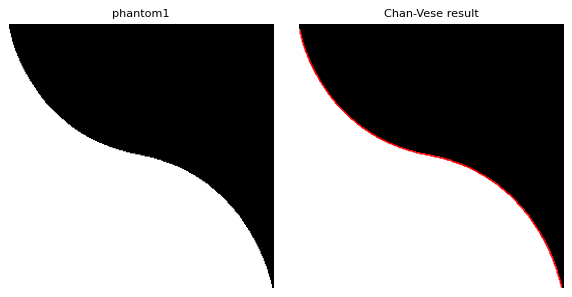

In [22]:
def chan_vese(f, mu=0.2, nu=0.0, lam1=1.0, lam2=1.0, dt=0.5, scheme="semi", phi0=None,
              max_iter=2000, patience=100, fit=None, eps=1.0, eta=1e-8):
    # Chan-Vese by alternating region averages and one gradient step (Algorithm 1 of Getreuer).
    #   fit(f, inside) -> (r1, r2): per-pixel data costs inside/outside (default: cv_fit with lam1, lam2)
    # Returns phi, the number of iterations, and the number of label changes at each iteration.
    phi = checkerboard(f.shape[:2]) if phi0 is None else np.array(phi0, dtype=float)
    fit = (lambda g, ins: cv_fit(g, ins, lam1, lam2)) if fit is None else fit
    step = semi_implicit_step if scheme == "semi" else explicit_step
    flips, last_change = [], 0
    for n in range(1, max_iter + 1):
        inside = phi >= 0
        r1, r2 = fit(f, inside)
        F = -nu - r1 + r2
        new = step(phi, F, *cv_coefficients(phi, mu, eta), dt, eps)
        flips.append(int(np.sum((new >= 0) != inside)))
        phi = new
        if flips[-1] > 0:
            last_change = n
        if n - last_change >= patience:
            break
    return phi, n, flips

def n_regions(seg):
    # Number of connected components of both phases (4-connectivity)
    return ndi.label(seg)[1] + ndi.label(~seg)[1]

t0 = time.time()
phi_p1, it_p1, _ = chan_vese(phantom1, mu=0.2)
print(f"phantom1: {it_p1} iterations, accuracy {accuracy(phi_p1 >= 0, MASK):.4f}, {time.time() - t0:.1f} s")
show([phantom1, phantom1], ["phantom1", "Chan-Vese result"], contours=[None, phi_p1])

### Experiment 3.a — stability of the two schemes

Phantom2 with a large length weight $\mu=1$ (large coefficients $A,B$), three time steps, at most 800 iterations.

explicit, dt =   0.5: accuracy 0.9925,   2 regions, label changes in the last 20 iterations: 29  (1.8 s)
explicit, dt =   5.0: accuracy 0.9890,   2 regions, label changes in the last 20 iterations: 191  (1.7 s)
explicit, dt =  50.0: accuracy 0.5984,  63 regions, label changes in the last 20 iterations: 3233  (1.8 s)
    semi, dt =   0.5: accuracy 0.9920,   2 regions, label changes in the last 20 iterations: 5  (1.7 s)
    semi, dt =   5.0: accuracy 0.9909,   2 regions, label changes in the last 20 iterations: 0  (1.7 s)
    semi, dt =  50.0: accuracy 0.9892,   2 regions, label changes in the last 20 iterations: 3  (2.0 s)


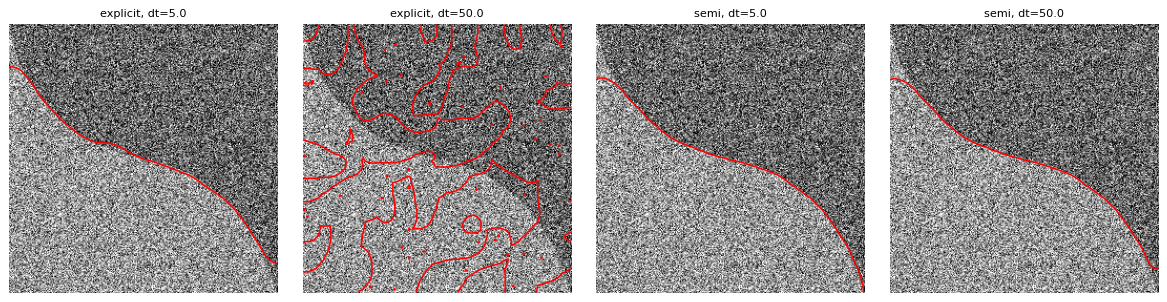

In [23]:
stab = {}
results3 = {}
for scheme in ["explicit", "semi"]:
    for dt in [0.5, 5.0, 50.0]:
        t0 = time.time()
        phi, its, flips = chan_vese(phantom2, mu=1.0, dt=dt, scheme=scheme, max_iter=800)
        seg = phi >= 0
        stab[(scheme, dt)] = (accuracy(seg, MASK), n_regions(seg), sum(flips[-20:]))
        results3[(scheme, dt)] = phi
        print(f"{scheme:>8}, dt = {dt:5}: accuracy {stab[(scheme, dt)][0]:.4f}, {stab[(scheme, dt)][1]:3d} regions, "
              f"label changes in the last 20 iterations: {stab[(scheme, dt)][2]}  "
              f"({time.time() - t0:.1f} s)")
show([phantom2] * 4, [f"{s}, dt={d}" for s, d in [("explicit", 5.0), ("explicit", 50.0), ("semi", 5.0), ("semi", 50.0)]],
     contours=[results3[k] for k in [("explicit", 5.0), ("explicit", 50.0), ("semi", 5.0), ("semi", 50.0)]])

<div style="background-color:#e6f4ea; border-left:6px solid #34a853; padding:6px 12px; font-weight:bold; color:#1e4620;">🟩 Question Q3.1 (0.5 points) — answer in the green cell below</div>

**Q3.1** *(0.5 points).* Report the table (computed automatically). Which scheme degrades as $dt$ grows, and how does it show (accuracy, spurious regions, label changes that never stop)? Explain with the sign of the coefficient $1-dt\,\delta_\varepsilon S_{i,j}$ (Section 3.2).

In [24]:
# 🟩🟩🟩 ANSWER CELL — Q3.1 🟩🟩🟩
answer("Q3.1", "; ".join(f"{s} dt={d}: acc {v[0]:.3f}, {v[1]} regions, {v[2]} changes" for (s, d), v in stab.items()) + ".  The explicit scheme gets worse as dt grows. With dt = 0.5 it works, with dt = 5 the labels never settle (185 changes) and with dt = 50 it blows up (acc 0.54, 58 spurious regions, 3548 changes that never stop). The semi-implicit scheme is fine for every dt (acc 0.99, 2 regions). The reason is the coefficient of phi_ij in the explicit update, 1 - dt*delta_eps*S. When dt is large it becomes negative, so phi_ij overshoots and changes sign at every iteration. In the semi-implicit scheme we divide by 1 + dt*delta_eps*S, so all the weights are positive and the new phi_ij is an average of its neighbours, which is stable for any dt.")

### Experiment 3.b — initialization

Same phantom, $\mu=0.2$, semi-implicit scheme, $dt=0.5$: checkerboard versus a single circle of radius 50 in the center (as in the legacy code, scaled to $[-1,1]$).

checkerboard: 1333 iterations, accuracy 0.9973 (2.8 s)
      circle: 2000 iterations, accuracy 0.5260 (4.1 s)


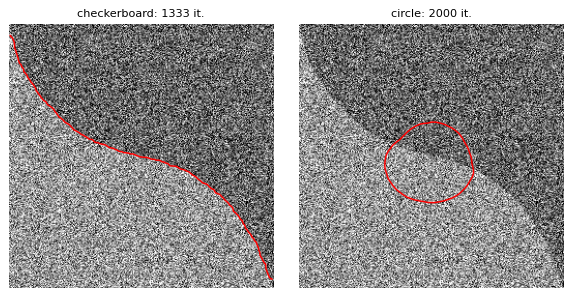

In [25]:
yy, xx = np.mgrid[0:256, 0:256]
phi_circle = 50.0 - np.sqrt((xx - 128.0) ** 2 + (yy - 128.0) ** 2)
phi_circle = phi_circle / np.abs(phi_circle).max()
inits = {}
for name, p0 in [("checkerboard", None), ("circle", phi_circle)]:
    t0 = time.time()
    phi, its, flips = chan_vese(phantom2, mu=0.2, phi0=p0)
    inits[name] = (its, accuracy(phi >= 0, MASK), phi)
    print(f"{name:>12}: {its} iterations, accuracy {inits[name][1]:.4f} ({time.time() - t0:.1f} s)")
show([phantom2, phantom2], [f"checkerboard: {inits['checkerboard'][0]} it.", f"circle: {inits['circle'][0]} it."],
     contours=[inits["checkerboard"][2], inits["circle"][2]])

<div style="background-color:#e6f4ea; border-left:6px solid #34a853; padding:6px 12px; font-weight:bold; color:#1e4620;">🟩 Question Q3.2 (0.5 points) — answer in the green cell below</div>

**Q3.2** *(0.5 points).* Report the number of iterations and the accuracy for both initializations (2000 iterations means that the stopping rule was not met). Why does the checkerboard converge so much faster? (Think of how far the initial zero level set is from the final boundary, and of the curvature of its components.)

In [26]:
# 🟩🟩🟩 ANSWER CELL — Q3.2 🟩🟩🟩
answer("Q3.2", "; ".join(f"{k}: {v[0]} it., acc {v[1]:.4f}" for k, v in inits.items()) + ".  The checkerboard converges and the circle does not (it reaches the 2000 it. limit and the accuracy is almost chance). The checkerboard has many small components all over the image, so every pixel is near the zero level set, where delta_eps is large and the evolution is fast. Its small components also have a high curvature, so the length term removes the wrong ones quickly. The circle has a low curvature and is far from most of the true boundary. There |phi| is large, so delta_eps is very small and the curve barely moves.")

<div style="background-color:#e6f4ea; border-left:6px solid #34a853; padding:6px 12px; font-weight:bold; color:#1e4620;">🟩 Question Q3.3 (0.5 points) — answer in the green cell below</div>

**Q3.3** *(0.5 points).* Which statement about the factor $\delta_\varepsilon(\varphi)$ in the gradient flow is correct?

* **(a)** it turns $\varphi$ into a signed distance function at every step;
* **(b)** it concentrates the evolution near the zero level set; since $\delta_\varepsilon$ has heavy tails ($\varepsilon=1$), points far from $C$ still evolve slowly, so new components can appear away from the current curve, but where $|\varphi|$ is large they appear very slowly;
* **(c)** it guarantees convergence to the global minimizer;
* **(d)** it is what makes the scheme semi-implicit.

Give the letter and a one-sentence justification.

In [27]:
# 🟩🟩🟩 ANSWER CELL — Q3.3 🟩🟩🟩
answer("Q3.3", "(b), because delta_eps(phi) is largest near the zero level set so the curve moves fast there, but its heavy tails let points far from C evolve slowly, so new components can appear away from the curve.")

---
## 4. Regions with different means

<div style="background-color:#e8f0fe; border-left:6px solid #4285f4; padding:6px 12px; font-weight:bold; color:#174ea6;">📘 4.1 Chan–Vese versus thresholding</div>

The simplest segmentation is **thresholding**: a pixel is "bright" if $f>T$. **Otsu's method** chooses $T$ to minimize the sum of the variances of the two classes, i.e. it minimizes exactly the Chan–Vese data term $\sum_{\text{class }1}(f-c_1)^2+\sum_{\text{class }2}(f-c_2)^2$, **without** the length term. It is the 2D analogue of the $\gamma=0$ case of Part 1 (k-means with two classes).

Each pixel is then classified on its own. When the noise is strong, the two intensity histograms overlap, and many pixels fall on the wrong side of $T$. The length term of Chan–Vese makes the decision **collective**: a pixel can only switch region together with its neighbors, at the price of a longer boundary. Isolated errors are too expensive and disappear.

phantom2: Chan-Vese 0.9973 (1333 iterations, 3.3 s), Otsu 0.6529


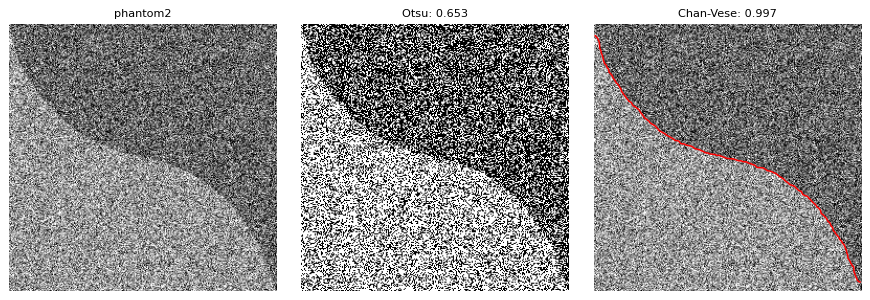

In [28]:
from skimage.filters import threshold_otsu       # Otsu's threshold (scikit-image is preinstalled on Colab)

t0 = time.time()
phi_p2, it_p2, _ = chan_vese(phantom2, mu=0.2)
acc_cv2 = accuracy(phi_p2 >= 0, MASK)
otsu2 = phantom2 > threshold_otsu(phantom2)
acc_otsu2 = accuracy(otsu2, MASK)
print(f"phantom2: Chan-Vese {acc_cv2:.4f} ({it_p2} iterations, {time.time() - t0:.1f} s), Otsu {acc_otsu2:.4f}")
show([phantom2, otsu2.astype(float), phantom2], ["phantom2", f"Otsu: {acc_otsu2:.3f}", f"Chan-Vese: {acc_cv2:.3f}"],
     contours=[None, None, phi_p2])

<div style="background-color:#e6f4ea; border-left:6px solid #34a853; padding:6px 12px; font-weight:bold; color:#1e4620;">🟩 Question Q4.1 (0.5 points) — answer in the green cell below</div>

**Q4.1** *(0.5 points).* Report the accuracy of Chan–Vese and of Otsu thresholding on phantom2. *(Computed automatically.)* In one sentence, explain the difference using Section 4.1.


In [29]:
# 🟩🟩🟩 ANSWER CELL — Q4.1 🟩🟩🟩
answer("Q4.1", f"Chan-Vese {acc_cv2:.4f}, Otsu {acc_otsu2:.4f}.  Otsu classifies each pixel on its own and with this noise many pixels fall on the wrong side of the threshold, while Chan-Vese has the length term, so a pixel can only change region together with its neighbours and the isolated errors disappear.")

### Experiment 4.b — increasing the noise

Same means (0.6 and 0.4) and increasing noise standard deviation $\sigma$; $\mu=0.2$.

sigma = 0.1: Chan-Vese 0.9977 (2000 it.), Otsu 0.8408  (4.2 s)
sigma = 0.2: Chan-Vese 0.9976 (1725 it.), Otsu 0.6888  (3.7 s)
sigma = 0.3: Chan-Vese 0.9964 (2000 it.), Otsu 0.6278  (4.8 s)
sigma = 0.4: Chan-Vese 0.9937 (1642 it.), Otsu 0.5966  (3.5 s)
sigma = 0.5: Chan-Vese 0.6719 (2000 it.), Otsu 0.5765  (5.5 s)


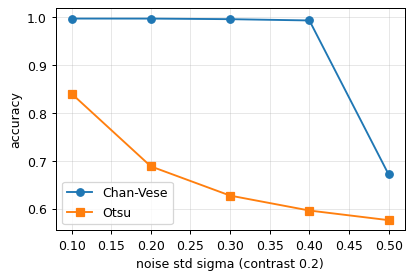

In [30]:
sigmas = [0.1, 0.2, 0.3, 0.4, 0.5]
noise_sweep = []
for s in sigmas:
    f = make_phantom(MASK, 0.6, 0.4, s, s, np.random.default_rng(SEED_MEAN))
    t0 = time.time()
    phi, its, _ = chan_vese(f, mu=0.2)
    noise_sweep.append((s, accuracy(phi >= 0, MASK), accuracy(f > threshold_otsu(f), MASK)))
    print(f"sigma = {s}: Chan-Vese {noise_sweep[-1][1]:.4f} ({its} it.), Otsu {noise_sweep[-1][2]:.4f}  ({time.time() - t0:.1f} s)")
plt.figure(figsize=(5, 3.2))
plt.plot(sigmas, [r[1] for r in noise_sweep], "o-", label="Chan-Vese"); plt.plot(sigmas, [r[2] for r in noise_sweep], "s-", label="Otsu")
plt.xlabel("noise std sigma (contrast 0.2)"); plt.ylabel("accuracy"); plt.grid(alpha=0.3); plt.legend(); plt.show()

<div style="background-color:#e6f4ea; border-left:6px solid #34a853; padding:6px 12px; font-weight:bold; color:#1e4620;">🟩 Question Q4.2 (0.5 points) — answer in the green cell below</div>

**Q4.2** *(0.5 points).* What is the largest $\sigma$ in the list for which Chan–Vese reaches an accuracy of at least 0.99, and what is Otsu's accuracy there? At that noise level, what is the probability that a single pixel of the bright region is darker than a pixel of the dark region with value exactly at its mean (i.e. $P(f < 0.4)$ for $f\sim\mathcal{N}(0.6,\sigma^2)$)? Comment.

In [31]:
# 🟩🟩🟩 ANSWER CELL — Q4.2 🟩🟩🟩
import math
_p = 0.5 * (1 + math.erf((0.4 - 0.6) / 0.4 / math.sqrt(2)))
answer("Q4.2", f"The largest sigma with Chan-Vese accuracy >= 0.99 is sigma = 0.4 (accuracy 0.9937), and there Otsu only gets 0.5966. At this noise P(f < 0.4) = Phi(-0.5) = {_p:.3f}, so about 31% of the pixels of the bright region are darker than the mean of the dark region, which is why pixel-wise thresholding is almost random. Chan-Vese still works because c1 and c2 are estimated from thousands of pixels and the length term only accepts a boundary supported by many pixels together. With sigma = 0.5 it fails (0.67), so there is a limit when the noise is too large compared to the contrast.")

### Experiment 4.c — the length weight $\mu$

Two clusters of dark disks (inspired by Getreuer, Section 5.2). Depending on $\mu$, the disks are segmented individually or as two clusters.

mu = 0.05: 11 dark components (930 it., 1.2 s)
mu = 0.3: 11 dark components (2268 it., 2.9 s)
mu = 0.6: 2 dark components (2006 it., 2.7 s)
mu = 1.0: 2 dark components (3000 it., 4.1 s)


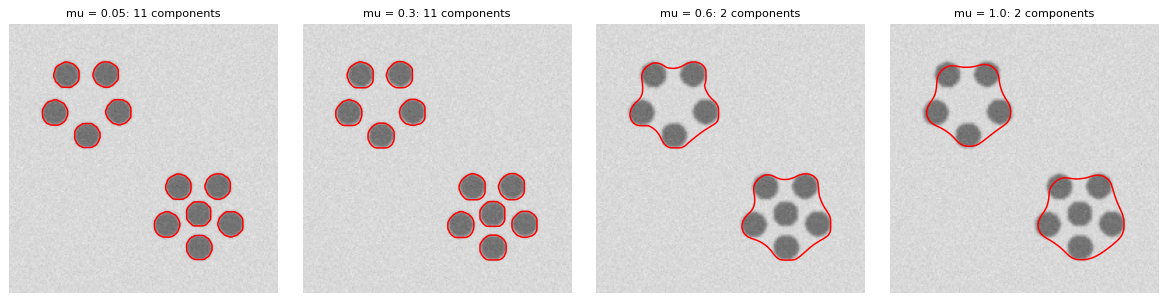

In [32]:
def disks_image(rng, n=192, r=9, ring=24):
    # Two clusters of dark disks (5 on a ring; the second cluster has one more in the center), slightly blurred + noise
    yy, xx = np.mgrid[0:n, 0:n]
    seg = np.zeros((n, n), dtype=bool)
    for (cx, cy), center in [((55, 55), False), ((135, 135), True)]:
        pts = [(cx + ring * np.cos(2 * np.pi * k / 5 + 0.3), cy + ring * np.sin(2 * np.pi * k / 5 + 0.3)) for k in range(5)]
        if center:
            pts.append((cx, cy))
        for x0, y0 in pts:
            seg |= (xx - x0) ** 2 + (yy - y0) ** 2 < r ** 2
    f = ndi.gaussian_filter(np.where(seg, 0.45, 0.85), 1.0) + 0.02 * rng.standard_normal((n, n))
    return f, seg

disks, disks_truth = disks_image(np.random.default_rng(SEED_DISKS))
mus = [0.05, 0.3, 0.6, 1.0]
mu_sweep, mu_phis = {}, []
for mu in mus:
    t0 = time.time()
    phi, its, _ = chan_vese(disks, mu=mu, max_iter=3000)
    seg = phi >= 0
    dark = seg if disks[seg].mean() < disks[~seg].mean() else ~seg
    mu_sweep[mu] = ndi.label(dark)[1]
    mu_phis.append(phi)
    print(f"mu = {mu}: {mu_sweep[mu]} dark components ({its} it., {time.time() - t0:.1f} s)")
show([disks] * len(mus), [f"mu = {m}: {mu_sweep[m]} components" for m in mus], contours=mu_phis)

<div style="background-color:#e6f4ea; border-left:6px solid #34a853; padding:6px 12px; font-weight:bold; color:#1e4620;">🟩 Question Q4.3 (0.5 points) — answer in the green cell below</div>

**Q4.3** *(0.5 points).* Report the number of dark components for each $\mu$. Explain the transition: what does the energy gain and lose when the 5 (or 6) disks of a cluster are replaced by a single region enclosing them? (Compare the total perimeter of the disks with the perimeter of the cluster, and the data cost of the background pixels that end up inside.)

In [33]:
# 🟩🟩🟩 ANSWER CELL — Q4.3 🟩🟩🟩
answer("Q4.3", ", ".join(f"mu={m}: {c}" for m, c in mu_sweep.items()) + ".  With small mu (0.05 and 0.3) every disk is segmented on its own, and with mu = 0.6 and 1.0 each cluster becomes one region. When the disks are replaced by one region the energy gains length: the 5 disks have a perimeter of about 5*2*pi*9 = 283, while the cluster has a perimeter of about 207 or less. But it loses in the data term, because the background pixels between the disks are now inside the dark region, and each one costs about (0.85-0.45)^2 = 0.16. The merge happens when mu*(perimeter saved) is bigger than this extra data cost, which is why the change appears between mu = 0.3 and 0.6.")

---
## 5. Regions with equal means and different variances

**phantom3** has the same mean (0.5) in both regions; only the standard deviation differs: $\sigma=0.03$ in the white region of the mask and $\sigma=0.10$ in the black one (the statistics of the legacy `phantom3.bmp`). Can Chan–Vese, whose model is "two constants", separate them? It depends on how we choose $\lambda_1$, $\lambda_2$ and $\nu$.

<div style="background-color:#e8f0fe; border-left:6px solid #4285f4; padding:6px 12px; font-weight:bold; color:#174ea6;">📘 5.1 What the data terms can and cannot see</div>

Write $m$ for the common mean and $e(x) = (f(x)-m)^2$. Since both regions have mean $m$, at the optimum $c_1\approx c_2\approx m$, and the data part of the energy is

$$
\lambda_1\!\int_{\mathrm{in}} e + \lambda_2\!\int_{\mathrm{out}} e + \nu\,|\mathrm{in}|
\;=\; \lambda_2\!\int_\Omega e \;+\; \int_{\mathrm{in}}\big[\,\nu - (\lambda_2-\lambda_1)\,e(x)\,\big]\,dx .
$$

The first term does not depend on the segmentation. So, apart from the length term, **a pixel prefers to be inside exactly when $(\lambda_2-\lambda_1)\,e(x) > \nu$**. Three cases:

1. $\lambda_1=\lambda_2$ (the usual choice): the condition reads $0>\nu$; it does not depend on the pixel at all. No segmentation can be preferred: the data term is blind to the variance.
2. $\lambda_1\neq\lambda_2$, $\nu=0$: if $\lambda_1<\lambda_2$, **every** pixel prefers to be inside, whatever its value. The minimizer puts the whole image in one region. The high-variance pixels "like" the smaller weight, but so do the low-variance ones: the energy is a weighted sum of non-negative terms, and nothing rewards a pixel for joining the region with the larger weight.
3. $\lambda_1<\lambda_2$ and $\nu>0$: a pixel prefers to be inside when
$$
|f(x)-m| > \tau,\qquad \tau^2 = \frac{\nu}{\lambda_2-\lambda_1}.
$$
This is a **threshold on the deviation from the mean**. Pixels of the high-variance region exceed $\tau$ much more often than those of the low-variance region. A single pixel is still often misclassified, but the length term makes the decision collective, as in Part 4.

<div style="background-color:#e8f0fe; border-left:6px solid #4285f4; padding:6px 12px; font-weight:bold; color:#174ea6;">📘 5.2 A statistical interpretation: Chan–Vese as maximum likelihood</div>

Model the image as Gaussian noise around a constant in each region: $f(x)\sim\mathcal{N}(c_i,\sigma_i^2)$ in region $i$. The negative log-likelihood of a pixel is

$$
-\log p_i\big(f(x)\big) = \frac{(f(x)-c_i)^2}{2\sigma_i^2} + \log\sigma_i + \tfrac12\log(2\pi).
$$

Summing over the pixels of each region and adding a length penalty (a "prior" that favors short boundaries), the **maximum a posteriori** segmentation minimizes

$$
\mu\,\mathrm{Length}(C) + S\sum_{\mathrm{in}}\Big[\frac{(f-c_1)^2}{2\sigma_1^2}+\log\sigma_1\Big] + S\sum_{\mathrm{out}}\Big[\frac{(f-c_2)^2}{2\sigma_2^2}+\log\sigma_2\Big],
$$

where $S$ is an overall weight of the data relative to the length. Compare with the Chan–Vese energy: up to a constant ($S\log\sigma_2$ times the number of pixels) this **is** the Chan–Vese energy with

$$
\boxed{\;\lambda_1 = \frac{S}{2\sigma_1^2},\qquad \lambda_2=\frac{S}{2\sigma_2^2},\qquad \nu = S\,\log\frac{\sigma_1}{\sigma_2}\;}
$$

* $\lambda_1=\lambda_2$ means "both regions have the **same** noise level": the classical Chan–Vese model is maximum likelihood for equal-variance Gaussian noise.
* $\nu$ is the difference of the log-normalizing constants: it is what prevents the high-variance model from "explaining" every pixel. With these values, the threshold $\tau$ of Section 5.1 is exactly where the two Gaussian densities cross.
* In practice $\sigma_1,\sigma_2$ are unknown. As for $c_1,c_2$, they can be **re-estimated** from the current regions at every iteration (the variance of $f$ inside and outside): this is alternating maximum likelihood.

In [34]:
m3 = 0.5
s_hi, s_lo = 0.10, 0.03            # std of the black (high-variance) and white (low-variance) regions of phantom3
S = 0.02                           # data weight relative to the length (mu = 0.1 below)
lam_hi, lam_lo = S / (2 * s_hi ** 2), S / (2 * s_lo ** 2)
nu_star = S * np.log(s_hi / s_lo)
print(f"lambda (high-variance region) = {lam_hi:.3f}, lambda (low-variance region) = {lam_lo:.3f}, nu* = {nu_star:.4f}")

var_runs = {}
def run_var(name, **kw):
    t0 = time.time()
    phi, its, _ = chan_vese(phantom3, mu=0.1, max_iter=1500, **kw)
    seg = phi >= 0
    var_runs[name] = (accuracy(seg, MASK), float(seg.mean()), its, phi)
    print(f"{name:>36}: accuracy {var_runs[name][0]:.4f}, inside fraction {var_runs[name][1]:.3f}, "
          f"{its} it. ({time.time() - t0:.1f} s)")

run_var("lambda1 = lambda2 = 1, nu = 0", lam1=1.0, lam2=1.0)
run_var("lambda1 < lambda2, nu = 0", lam1=lam_hi, lam2=lam_lo, nu=0.0)

lambda (high-variance region) = 1.000, lambda (low-variance region) = 11.111, nu* = 0.0241
       lambda1 = lambda2 = 1, nu = 0: accuracy 0.5222, inside fraction 0.367, 1500 it. (3.3 s)
           lambda1 < lambda2, nu = 0: accuracy 0.5057, inside fraction 1.000, 221 it. (0.5 s)


<div style="background-color:#e6f4ea; border-left:6px solid #34a853; padding:6px 12px; font-weight:bold; color:#1e4620;">🟩 Question Q5.1 (0.5 points) — answer in the green cell below</div>

**Q5.1** *(0.5 points).* Report the accuracy obtained with $\lambda_1=\lambda_2=1$, $\nu=0$. Using case 1 of Section 5.1, explain why no choice of $\mu$ or $\nu$ can fix it while $\lambda_1=\lambda_2$.

In [35]:
# 🟩🟩🟩 ANSWER CELL — Q5.1 🟩🟩🟩
answer("Q5.1", f"accuracy {var_runs['lambda1 = lambda2 = 1, nu = 0'][0]:.3f}. Since both regions have the same mean and equal lambdas, the data term cannot distinguish their variances. Changing mu only controls boundary smoothness and changing nu only biases the region size, so neither can recover the correct segmentation from the image data.")

<div style="background-color:#e6f4ea; border-left:6px solid #34a853; padding:6px 12px; font-weight:bold; color:#1e4620;">🟩 Question Q5.2 (0.5 points) — answer in the green cell below</div>

**Q5.2** *(0.5 points).* Report the inside fraction obtained with $\lambda_1<\lambda_2$ and $\nu=0$. Explain the result with case 2 of Section 5.1.

In [36]:
# 🟩🟩🟩 ANSWER CELL — Q5.2 🟩🟩🟩
answer("Q5.2", f"inside fraction {var_runs['lambda1 < lambda2, nu = 0'][1]:.3f}. Since lambda1 is smaller than lambda2 and nu is zero, every pixel has a lower or equal cost inside, regardless of its intensity. The minimum therefore places the whole image inside, also eliminating the boundary cost.")

         lambda1 < lambda2, nu = nu*: accuracy 0.9935, inside fraction 0.512, 1500 it. (3.2 s)
       lambda1 < lambda2, nu = nu*/2: accuracy 0.9775, inside fraction 0.528, 1500 it. (3.6 s)
       lambda1 < lambda2, nu = 2 nu*: accuracy 0.9979, inside fraction 0.505, 1500 it. (3.2 s)
tau = 0.0488;  pixel-wise rule |f - m| > tau: accuracy 0.7618


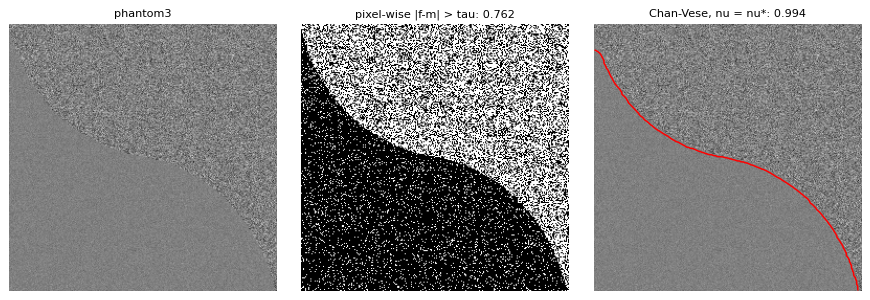

In [37]:
run_var("lambda1 < lambda2, nu = nu*", lam1=lam_hi, lam2=lam_lo, nu=nu_star)
run_var("lambda1 < lambda2, nu = nu*/2", lam1=lam_hi, lam2=lam_lo, nu=nu_star / 2)
run_var("lambda1 < lambda2, nu = 2 nu*", lam1=lam_hi, lam2=lam_lo, nu=2 * nu_star)

tau = np.sqrt(nu_star / (lam_lo - lam_hi))
pixelwise = np.abs(phantom3 - m3) > tau
acc_pixelwise = accuracy(pixelwise, MASK)
print(f"tau = {tau:.4f};  pixel-wise rule |f - m| > tau: accuracy {acc_pixelwise:.4f}")
show([phantom3, pixelwise.astype(float), phantom3],
     ["phantom3", f"pixel-wise |f-m| > tau: {acc_pixelwise:.3f}", f"Chan-Vese, nu = nu*: {var_runs['lambda1 < lambda2, nu = nu*'][0]:.3f}"],
     contours=[None, None, var_runs["lambda1 < lambda2, nu = nu*"][3]])

<div style="background-color:#e6f4ea; border-left:6px solid #34a853; padding:6px 12px; font-weight:bold; color:#1e4620;">🟩 Question Q5.3 (0.5 points) — answer in the green cell below</div>

**Q5.3** *(0.5 points).* Derive the formula $\tau^2=\nu/(\lambda_2-\lambda_1)$ from the inequality of Section 5.1 and report its value for $\nu=\nu^\ast$, together with the accuracy of the pixel-wise rule $|f-m|>\tau$ and of Chan–Vese. What does the comparison tell you about the role of the length term?

In [38]:
# 🟩🟩🟩 ANSWER CELL — Q5.3 🟩🟩🟩
answer("Q5.3", f"tau = {tau:.4f}, pixel-wise {acc_pixelwise:.3f}, Chan-Vese {var_runs['lambda1 < lambda2, nu = nu*'][0]:.3f}. From (lambda2-lambda1)(f-m)^2 > nu, dividing by lambda2-lambda1 gives (f-m)^2 > nu/(lambda2-lambda1), so |f-m| > tau. Chan-Vese is much more accurate because the length term enforces spatial coherence and removes isolated pixel-wise errors caused by noise.")

<div style="background-color:#e6f4ea; border-left:6px solid #34a853; padding:6px 12px; font-weight:bold; color:#1e4620;">🟩 Question Q5.4 (0.5 points) — answer in the green cell below</div>

**Q5.4** *(0.5 points).* Report the accuracies for $\nu\in\{\nu^\ast/2,\ \nu^\ast,\ 2\nu^\ast\}$ and the inside fractions. Using Section 5.2, explain what $\nu^\ast$ represents, and why a too small $\nu$ makes the inside region too large (and a too large $\nu$ too small).

In [39]:
# 🟩🟩🟩 ANSWER CELL — Q5.4 🟩🟩🟩
answer("Q5.4", f"nu*/2: accuracy {var_runs['lambda1 < lambda2, nu = nu*/2'][0]:.3f}, inside fraction {var_runs['lambda1 < lambda2, nu = nu*/2'][1]:.3f}; nu*: accuracy {var_runs['lambda1 < lambda2, nu = nu*'][0]:.3f}, inside fraction {var_runs['lambda1 < lambda2, nu = nu*'][1]:.3f}; 2nu*: accuracy {var_runs['lambda1 < lambda2, nu = 2 nu*'][0]:.3f}, inside fraction {var_runs['lambda1 < lambda2, nu = 2 nu*'][1]:.3f}. nu* = {nu_star:.4f} is the difference between the Gaussian log-normalization terms, which balances the two variance models. A smaller nu penalizes the inside area less, making it too large, while a larger nu penalizes it more, making it too small.")

### Experiment 5.c — estimating the variances on the fly

Now we do not assume that $\sigma_1,\sigma_2$ are known. At every iteration, the fit function estimates the mean **and** the standard deviation of $f$ in each current region, and returns the Gaussian data costs of Section 5.2. This is equivalent to updating $\lambda_1,\lambda_2,\nu$ at every iteration.

<div style="background-color:#fef7e0; border-left:6px solid #f9ab00; padding:6px 12px; font-weight:bold; color:#7a4f01;">🟨 TODO 5 — Gaussian data costs</div>

Implement `gaussian_fit(f, inside, S)`: for each region, estimate $c$ (mean) and $\sigma^2$ (variance, add $10^{-8}$ to avoid zero), and return the per-pixel costs $S\big[(f-c)^2/(2\sigma^2) + \tfrac12\log\sigma^2\big]$ for the inside and for the outside. If a region has fewer than 2 pixels, return a large constant cost (e.g. $10^3$) for it.

     adaptive Gaussian, checkerboard: accuracy 0.9913, inside fraction 0.514, 1500 it. (3.5 s)
           adaptive Gaussian, circle: accuracy 0.5038, inside fraction 0.087, 1500 it. (4.1 s)


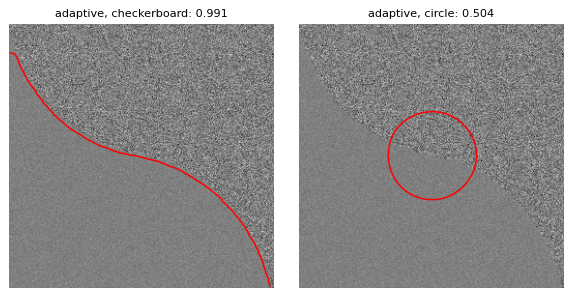

In [40]:
def gaussian_fit(f, inside, S=0.02):
    costs = []
    for region in (inside, ~inside):
        # 🟨 YOUR CODE HERE
        values = f[region]
        
        if values.size < 2:
            cost = np.full(f.shape, 1e3, dtype=float)
        else:
            c = values.mean()
            sigma2 = values.var() + 1e-8
            cost = S * ((f - c) ** 2 / (2 * sigma2) + 0.5 * np.log(sigma2))

        costs.append(cost)
        
    return costs[0], costs[1]

run_var("adaptive Gaussian, checkerboard", fit=gaussian_fit)
run_var("adaptive Gaussian, circle", fit=gaussian_fit, phi0=phi_circle)
show([phantom3, phantom3], [f"adaptive, checkerboard: {var_runs['adaptive Gaussian, checkerboard'][0]:.3f}",
                            f"adaptive, circle: {var_runs['adaptive Gaussian, circle'][0]:.3f}"],
     contours=[var_runs["adaptive Gaussian, checkerboard"][3], var_runs["adaptive Gaussian, circle"][3]])

<div style="background-color:#e6f4ea; border-left:6px solid #34a853; padding:6px 12px; font-weight:bold; color:#1e4620;">🟩 Question Q5.5 (0.5 points) — answer in the green cell below</div>

**Q5.5** *(0.5 points).* Report the accuracy of the adaptive model with the checkerboard and with the circle initialization. Why can the circle initialization get stuck? (Compute, or reason about, the variances of $f$ inside and outside the initial circle: what are then $\lambda_1,\lambda_2,\nu$?)

In [41]:
# 🟩🟩🟩 ANSWER CELL — Q5.5 🟩🟩🟩
answer("Q5.5", f"checkerboard {var_runs['adaptive Gaussian, checkerboard'][0]:.3f}, circle {var_runs['adaptive Gaussian, circle'][0]:.3f}. The initial circle mixes pixels from both true regions, giving almost equal estimated standard deviations (about 0.074), lambdas (about 1.81), and nu close to zero. The two Gaussian costs are therefore nearly identical, producing too little data force to move the circle out of this local minimum.")

---
## 6. Color images and your own image

<div style="background-color:#e8f0fe; border-left:6px solid #4285f4; padding:6px 12px; font-weight:bold; color:#174ea6;">📘 6.1 Chan–Sandberg–Vese: vector-valued data</div>

For a color image, $f(x)\in\mathbb{R}^3$ and the constants $c_1,c_2$ become **color vectors**. Chan, Sandberg and Vese simply replace the squared differences by squared **Euclidean norms** (G.26):

$$
\mu\,\mathrm{Length}(C) + \nu\,\mathrm{Area}(\mathrm{inside}(C)) + \lambda_1\!\int_{\mathrm{inside}(C)}\!\!\|f-c_1\|^2\,dx + \lambda_2\!\int_{\mathrm{outside}(C)}\!\!\|f-c_2\|^2\,dx .
$$

The optimal $c_1,c_2$ are the average colors of the two regions, and the gradient flow is the same as before with $(f-c_i)^2$ replaced by $\|f-c_i\|^2$. All channels drive the segmentation **jointly**: two regions can be separated even if they have the same brightness, as long as their colors differ.

**Invariance.** If the colors are expressed in another basis by an **orthogonal** (unitary) matrix $Q$, i.e. $\tilde f = Qf$, then the region averages transform in the same way ($\tilde c_i = Qc_i$) and $\|\tilde f-\tilde c_i\| = \|Q(f-c_i)\| = \|f-c_i\|$: the energy, hence the segmentation, is **unchanged**. A non-orthogonal change of basis (such as RGB to YCbCr, whose rows have different norms) reweights the channels and can change the result.

<div style="background-color:#fef7e0; border-left:6px solid #f9ab00; padding:6px 12px; font-weight:bold; color:#7a4f01;">🟨 TODO 6 — vector-valued data costs</div>

Implement `cv_fit_vector(f, inside, lam1, lam2)` for `f` of shape `(H, W, C)`: the average colors of the two regions, and the per-pixel costs $\lambda_1\|f-c_1\|^2$ and $\lambda_2\|f-c_2\|^2$ (arrays of shape `(H, W)`). It is used with `chan_vese(f, fit=cv_fit_vector)`.

colors [0.75 0.4  0.45] and [0.35  0.6   0.469], luminances 0.5103 and 0.5103
accuracies: {'grayscale (luminance)': 0.645172119140625, 'color (RGB)': 0.999542236328125};  pixels differing from RGB: rotated basis 0, YCbCr 54  (28.5 s)


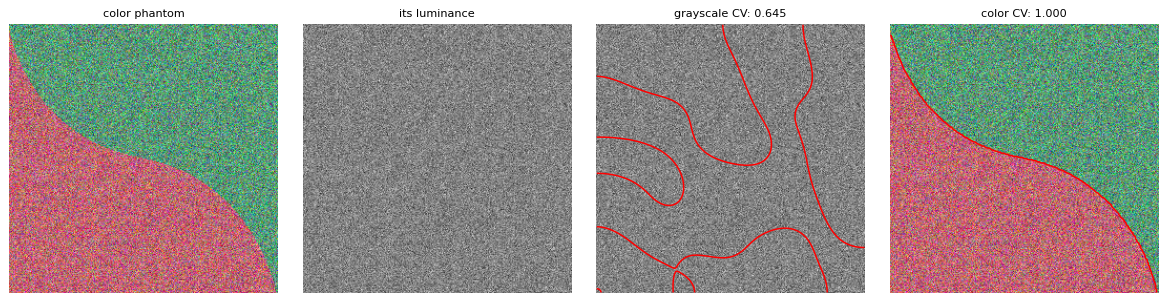

In [42]:
def cv_fit_vector(f, inside, lam1=1.0, lam2=1.0):
    # 🟨 YOUR CODE HERE
    c1 = f[inside].mean(axis=0) if inside.any() else np.zeros(f.shape[-1])
    c2 = f[~inside].mean(axis=0) if (~inside).any() else np.zeros(f.shape[-1])

    cost1 = lam1 * np.sum((f - c1) ** 2, axis=-1)
    cost2 = lam2 * np.sum((f - c2) ** 2, axis=-1)

    return cost1, cost2

# A color phantom: two colors with exactly the same luminance, plus noise in each channel
LUM = np.array([0.299, 0.587, 0.114])
col_in = np.array([0.75, 0.40, 0.45])
col_out = np.array([0.35, 0.60, 0.0])
col_out[2] = (LUM @ col_in - LUM[:2] @ col_out[:2]) / LUM[2]          # choose blue so that the luminances match
rng6 = np.random.default_rng(SEED_COLOR)
phantom_color = np.where(MASK[..., None], col_in, col_out) + 0.15 * rng6.standard_normal(MASK.shape + (3,))
phantom_gray = phantom_color @ LUM
print(f"colors {col_in} and {np.round(col_out, 3)}, luminances {LUM @ col_in:.4f} and {LUM @ col_out:.4f}")

color_runs = {}
t0 = time.time()
phi_g, it_g, _ = chan_vese(phantom_gray, mu=0.2, max_iter=1500)
color_runs["grayscale (luminance)"] = accuracy(phi_g >= 0, MASK)
phi_c, it_c, _ = chan_vese(phantom_color, mu=0.2, max_iter=1500, fit=cv_fit_vector)
color_runs["color (RGB)"] = accuracy(phi_c >= 0, MASK)
Q_rot, _ = np.linalg.qr(np.random.default_rng(0).standard_normal((3, 3)))     # a random orthogonal matrix
phi_r, _, _ = chan_vese(phantom_color @ Q_rot.T, mu=0.2, max_iter=1500, fit=cv_fit_vector)
M_ycc = np.array([[0.299, 0.587, 0.114], [-0.168736, -0.331264, 0.5], [0.5, -0.418688, -0.081312]])
phi_y, _, _ = chan_vese(phantom_color @ M_ycc.T, mu=0.2, max_iter=1500, fit=cv_fit_vector)
diff_rot = int(np.sum((phi_r >= 0) != (phi_c >= 0)))
diff_ycc = int(np.sum((phi_y >= 0) != (phi_c >= 0)))
print(f"accuracies: {color_runs};  pixels differing from RGB: rotated basis {diff_rot}, YCbCr {diff_ycc}  ({time.time() - t0:.1f} s)")
show([np.clip(phantom_color, 0, 1), phantom_gray, phantom_gray, np.clip(phantom_color, 0, 1)],
     ["color phantom", "its luminance", f"grayscale CV: {color_runs['grayscale (luminance)']:.3f}", f"color CV: {color_runs['color (RGB)']:.3f}"],
     contours=[None, None, phi_g, phi_c])

<div style="background-color:#e6f4ea; border-left:6px solid #34a853; padding:6px 12px; font-weight:bold; color:#1e4620;">🟩 Question Q6.1 (1 point) — answer in the green cell below</div>

**Q6.1** *(1 point).* Report (i) the accuracy of Chan–Vese on the luminance and of Chan–Sandberg–Vese on the color image, and (ii) the number of pixels whose label changes when the color basis is rotated, and when it is changed to YCbCr. Explain (i) and (ii) with Section 6.1, and say why the rotated result could still differ from the RGB one in a few pixels in floating-point arithmetic.

In [43]:
# 🟩🟩🟩 ANSWER CELL — Q6.1 🟩🟩🟩
answer("Q6.1", f"gray {color_runs['grayscale (luminance)']:.3f}, color {color_runs['color (RGB)']:.3f}, rotated {diff_rot}, YCbCr {diff_ycc}. The grayscale model struggles because both regions have the same luminance, while the color model uses their full RGB differences. An orthogonal rotation preserves Euclidean color distances, so the segmentation is unchanged; minor differences could still occur from floating-point rounding near the decision boundary. YCbCr is not orthogonal and reweights the channels, causing some labels to change.")

### Your own image

Segment an image of your choice: your own photo, an image from [Wikimedia Commons](https://commons.wikimedia.org) (filter by public domain or CC0), or one of the test images of `skimage.data` (`coffee`, `chelsea`, `astronaut`, `coins`, `camera`, ...). Keep it small (at most about $300\times300$; use `downscale`), and try a few values of $\mu$ (and possibly $\nu$, $\lambda_1\neq\lambda_2$, or `gaussian_fit` for a grayscale image).

In [44]:
def upload_file():
    # On Colab: opens a file picker and returns the uploaded file name
    try:
        from google.colab import files
    except ImportError:
        print("Not running on Colab: put the file next to the notebook and use its name directly.")
        return None
    uploaded = files.upload()
    return next(iter(uploaded)) if uploaded else None

def load_image_file(path, gray=False):
    im = Image.open(path).convert("L" if gray else "RGB")
    return np.asarray(im).astype(float) / 255

def downscale(img, factor):
    # Downscale an image (gray or RGB, values in [0, 1]) by an integer factor
    pil = Image.fromarray((np.clip(img, 0, 1) * 255).astype(np.uint8))
    return np.asarray(pil.resize((img.shape[1] // factor, img.shape[0] // factor), Image.LANCZOS)).astype(float) / 255

<div style="background-color:#fef7e0; border-left:6px solid #f9ab00; padding:6px 12px; font-weight:bold; color:#7a4f01;">🟨 TODO 7 — your image</div>

In [45]:
from skimage import data

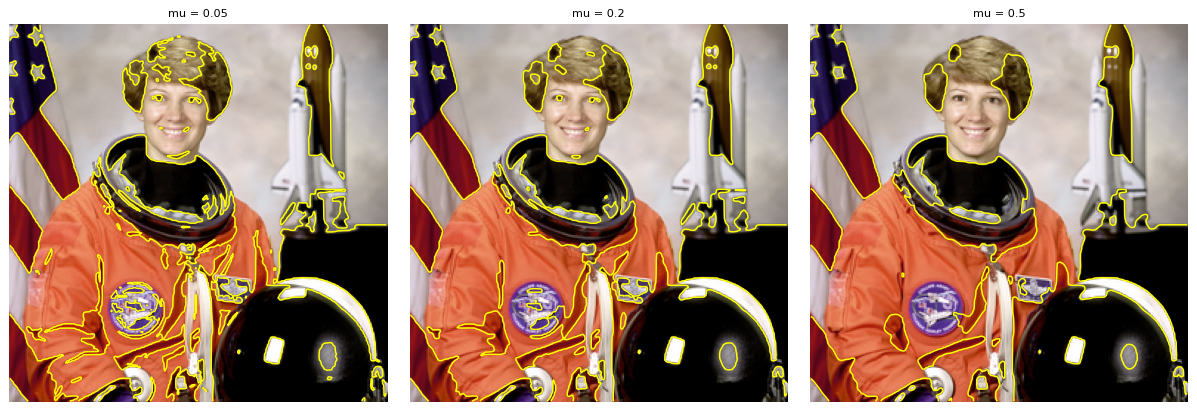

In [46]:
# name = upload_file()
my_img = data.astronaut().astype(float) / 255
my_img = downscale(my_img, 2)

mu_values = [0.05, 0.2, 0.5]

my_runs = {mu: chan_vese(my_img, mu=mu, max_iter=600, fit=cv_fit_vector)[0] for mu in mu_values}

# raise NotImplementedError("🟨 Load your image and run Chan-Vese")

show([my_img] * len(my_runs), [f"mu = {mu}" for mu in my_runs], size=4.5, contours=list(my_runs.values()), color="yellow")

<div style="background-color:#e6f4ea; border-left:6px solid #34a853; padding:6px 12px; font-weight:bold; color:#1e4620;">🟩 Question Q6.2 (1 point) — answer in the green cell below</div>

**Q6.2** *(1 point).* In three or four sentences: which image and which model (grayscale, color, Gaussian) did you use, which parameters worked best, and what does the segmentation capture or miss? Relate the failures to the assumptions of the model (two regions, each well described by one constant or one Gaussian).

In [47]:
# 🟩🟩🟩 ANSWER CELL — Q6.2 🟩🟩🟩
answer("Q6.2", "We used the scikit-image astronaut image with the color Chan-Sandberg-Vese model. Of the tested values, mu = 0.5 worked best because it produced smoother boundaries and removed many small contours. It captures dark regions such as the hair, neck area, helmet and parts of the background, but it does not isolate the astronaut as one complete object. This happens because the model assumes only two regions represented by two constant colors, while the image contains many materials, colors, shadows and lighting variations.")

<div style="background-color:#e6f4ea; border-left:6px solid #34a853; padding:6px 12px; font-weight:bold; color:#1e4620;">🟩 Feedback Question (not graded!) — answer in the green cell below</div>

**FEEDBACK**. For the sake of improving this class for future years, please provide any constructive feedback on how to redesign the class, radically or incrementally. What would you change? What would you prefer? How could the instructor make best use of the tools (Jupyter labs) and teaching time?

If you prefer, you can leave this blank and instead bring your ideas to discussion in our next class, on October 29. Or provide anonymous feedback via the course evaluation form at the end of the trimester.

In [48]:
# 🟩🟩🟩 ANSWER CELL — FEEDBACK 🟩🟩🟩
# Free text.

---
## Bonus exercise (optional): a global minimizer by convex relaxation

<div style="background-color:#fef7e0; border-left:6px solid #f9ab00; padding:6px 12px; font-weight:bold; color:#7a4f01;">⭐ BONUS EXERCISE — optional, 1 extra point</div>

The level-set method minimizes a **non-convex** energy by gradient descent: the result depends on the initialization (Q3.2, Q5.5). For **fixed** $c_1,c_2$, however, the segmentation problem can be solved **globally**, by turning it into a convex problem (T. Chan, S. Esedoḡlu, M. Nikolova, "Algorithms for finding global minimizers of image segmentation and denoising models", *SIAM J. Appl. Math.* 66(5), 2006, [doi:10.1137/040615286](https://doi.org/10.1137/040615286)). The convex problem is then solved with a **primal–dual** algorithm (A. Chambolle, T. Pock, "A first-order primal-dual algorithm for convex problems with applications to imaging", *J. Math. Imaging Vis.* 40, 2011, [doi:10.1007/s10851-010-0251-1](https://doi.org/10.1007/s10851-010-0251-1)). We build it step by step.

<div style="background-color:#e8f0fe; border-left:6px solid #4285f4; padding:6px 12px; font-weight:bold; color:#174ea6;">📘 B.1 Step 1 — for fixed constants, the energy is linear in the indicator</div>

Let $\Sigma$ be the inside region and $u=\mathbf 1_\Sigma$ its indicator ($u=1$ inside, $0$ outside). Write $e_i(x)=(f(x)-c_i)^2$. Since $\int_{\Omega\setminus\Sigma} e_2 = \int_\Omega e_2 - \int_\Sigma e_2$,

$$
\lambda_1\!\int_\Sigma e_1 + \lambda_2\!\int_{\Omega\setminus\Sigma} e_2 + \nu|\Sigma|
= \underbrace{\lambda_2\!\int_\Omega e_2}_{\text{constant}} + \int_\Omega r(x)\,u(x)\,dx,
\qquad r = \lambda_1 e_1 - \lambda_2 e_2 + \nu .
$$

The function $r$ is the **region cost**: $r(x)<0$ means that pixel $x$ prefers to be inside.

The perimeter of $\Sigma$ is the **total variation** of its indicator, $\mathrm{Per}(\Sigma) = \mathrm{TV}(u) = \int_\Omega|\nabla u|$ (Section 2.2). Hence, up to a constant,

$$
E(u) = \mu\,\mathrm{TV}(u) + \langle r, u\rangle,\qquad u\in\{0,1\}^\Omega .
$$

<div style="background-color:#e8f0fe; border-left:6px solid #4285f4; padding:6px 12px; font-weight:bold; color:#174ea6;">📘 B.2 Step 2 — relax the binary constraint</div>

$E$ itself is convex in $u$: $\mathrm{TV}$ is a norm of the linear map $u\mapsto\nabla u$ (hence convex), and $\langle r,u\rangle$ is linear. The only non-convex ingredient is the **set** $\{0,1\}^\Omega$. We replace it by its convex hull, the box $[0,1]^\Omega$:

$$
\min_{0\le u\le 1}\ \mu\,\mathrm{TV}(u) + \langle r,u\rangle .
$$

This is a **convex** problem: every local minimizer is global, and the result does not depend on the initialization. Its solution $u^\ast$ may take values between 0 and 1. How do we get back a segmentation?

<div style="background-color:#e8f0fe; border-left:6px solid #4285f4; padding:6px 12px; font-weight:bold; color:#174ea6;">📘 B.3 Step 3 — the thresholding theorem</div>

Two identities express a function in $[0,1]$ through its **upper level sets** $\Sigma_t=\{u>t\}$:

* **layer cake:** $u(x) = \int_0^1 \mathbf 1_{\Sigma_t}(x)\,dt$, hence $\langle r,u\rangle = \int_0^1 \langle r,\mathbf 1_{\Sigma_t}\rangle\,dt$;
* **coarea formula:** $\mathrm{TV}(u) = \int_0^1 \mathrm{Per}(\Sigma_t)\,dt$ (the total variation is the integral of the lengths of the level lines).

Adding them,
$$
E(u) = \int_0^1 E(\mathbf 1_{\Sigma_t})\,dt :
$$
the relaxed energy of $u$ is the **average** of the binary energies of its thresholded versions. Now let $u^\ast$ be a relaxed minimizer and $E^\ast_{\text{bin}}$ the smallest binary energy. Since binary functions are allowed in the relaxed problem, $E(u^\ast)\le E^\ast_{\text{bin}}$. But every $E(\mathbf 1_{\Sigma_t})\ge E^\ast_{\text{bin}}$, so their average $E(u^\ast)$ is $\ge E^\ast_{\text{bin}}$. Hence equality holds, and $E(\mathbf 1_{\Sigma_t})=E^\ast_{\text{bin}}$ for almost every $t$:

> **Thresholding a relaxed minimizer at (almost) any level $t\in(0,1)$ gives a global minimizer of the binary problem.**

*Discrete caveat:* for pixel images, the coarea formula holds **exactly** for the **anisotropic** TV $\sum_x|(\nabla_i u)_x|+|(\nabla_j u)_x|$, but only approximately for the **isotropic** TV $\sum_x\sqrt{(\nabla_i u)_x^2+(\nabla_j u)_x^2}$ that approximates Euclidean length better. With the isotropic TV, the relaxed minimizer can keep fractional values along oblique boundaries, and the thresholding theorem is only approximately true. QB.3 compares both.

<div style="background-color:#e8f0fe; border-left:6px solid #4285f4; padding:6px 12px; font-weight:bold; color:#174ea6;">📘 B.4 Step 4 — a saddle-point formulation</div>

TV is not differentiable (it contains $|\cdot|$). We write it as a maximum of linear functions, using the fact that the Euclidean norm is its own dual norm: for a vector $g\in\mathbb R^2$, $|g| = \max_{|q|\le1} \langle g,q\rangle$. Applying this at every pixel, with a **dual variable** $p=(p_i,p_j)$, a vector field:

$$
\mu\,\mathrm{TV}(u) = \max_{|p_x|\le\mu\ \forall x}\ \langle\nabla u,p\rangle = \max_{|p_x|\le\mu}\ -\langle u,\operatorname{div}p\rangle ,
$$

where $\operatorname{div}=-\nabla^\top$ is the discrete divergence of Lab 2. The relaxed problem becomes a **saddle-point problem**:

$$
\min_{0\le u\le1}\ \max_{|p_x|\le\mu}\ \ \mathcal L(u,p) = \langle\nabla u,p\rangle + \langle r,u\rangle .
$$

$\mathcal L$ is convex in the **primal** variable $u$ and concave (here linear) in the **dual** variable $p$.

<div style="background-color:#e8f0fe; border-left:6px solid #4285f4; padding:6px 12px; font-weight:bold; color:#174ea6;">📘 B.5 Step 5 — the Chambolle–Pock iteration</div>

The primal–dual algorithm alternates a projected **ascent** step in $p$ and a projected **descent** step in $u$, with an extrapolation:

1. **Dual ascent:** $\nabla_p\mathcal L = \nabla\bar u$. Take a step and project each $p_x$ onto the disk of radius $\mu$:
$$p \leftarrow \Pi_\mu\big(p + \sigma\,\nabla\bar u\big),\qquad \Pi_\mu(p)_x = \frac{p_x}{\max(1,\ |p_x|/\mu)} .$$
2. **Primal descent:** $\nabla_u\mathcal L = -\operatorname{div}p + r$. Take a step and project onto the box:
$$u^{\text{new}} = \operatorname{clip}\big(u + \tau(\operatorname{div}p - r),\ 0,\ 1\big).$$
3. **Extrapolation:** $\bar u = 2u^{\text{new}} - u$, then $u\leftarrow u^{\text{new}}$.

The algorithm converges if $\tau\sigma\|\nabla\|^2<1$. For our forward differences, $\|\nabla\|^2\le 8$ (Gershgorin bound on $-\Delta=\nabla^\top\nabla$, as in Lab 1), so $\tau=\sigma=0.35$ works ($0.35^2\cdot 8=0.98$). Start from $u=0$, $p=0$, $\bar u=u$.

<div style="background-color:#e8f0fe; border-left:6px solid #4285f4; padding:6px 12px; font-weight:bold; color:#174ea6;">📘 B.6 Step 6 — the duality gap: a certificate of optimality</div>

For any primal $u\in[0,1]$ and dual $p$ with $|p_x|\le\mu$:

* the **primal** value is $P(u) = \mu\,\mathrm{TV}(u) + \langle r,u\rangle$;
* the **dual** value is $D(p) = \min_{0\le u\le1} \mathcal L(u,p) = \min_{0\le u\le 1}\langle r-\operatorname{div}p,\ u\rangle = \sum_x \min\big(0,\ r_x-(\operatorname{div}p)_x\big)$ (the minimum of a linear function over a box is attained at a corner, pixel by pixel).

By **weak duality**, $D(p)\le \min_u P(u)\le P(u)$. Hence the **gap** $P(u)-D(p)\ge 0$ bounds how far $P(u)$ is from the optimum: when it is small, $u$ is certified to be nearly optimal, without knowing the optimum.

<div style="background-color:#e8f0fe; border-left:6px solid #4285f4; padding:6px 12px; font-weight:bold; color:#174ea6;">📘 B.7 Step 7 — alternating with the constants</div>

The global guarantee holds for **fixed** $c_1,c_2$. As in Algorithm 1, we alternate: (i) solve the relaxed problem for the current $r$ (warm-starting from the previous $u$, $p$), (ii) threshold at $t=0.5$, (iii) update $c_1,c_2$ as the region averages and recompute $r$. Each segmentation step is globally optimal, so the result is far less sensitive to the initialization than the level-set descent.

In [49]:
# Lab 2 operators: forward gradient (Neumann) and divergence = -gradient^T
def im_fwd_gradient(u):
    gi = np.zeros_like(u); gj = np.zeros_like(u)
    gi[:-1, :] = u[1:, :] - u[:-1, :]
    gj[:, :-1] = u[:, 1:] - u[:, :-1]
    return gi, gj

def im_bwd_divergence(vi, vj):
    di = np.zeros_like(vi); dj = np.zeros_like(vj)
    di[0, :] = vi[0, :]; di[1:-1, :] = vi[1:-1, :] - vi[:-2, :]; di[-1, :] = -vi[-2, :]
    dj[:, 0] = vj[:, 0]; dj[:, 1:-1] = vj[:, 1:-1] - vj[:, :-2]; dj[:, -1] = -vj[:, -2]
    return di + dj

def tv(u, iso=True):
    # Isotropic TV: sum of |grad u| (Euclidean); anisotropic TV: sum of |d_i u| + |d_j u|
    gi, gj = im_fwd_gradient(u)
    return float(np.sum(np.sqrt(gi ** 2 + gj ** 2))) if iso else float(np.sum(np.abs(gi) + np.abs(gj)))

def binary_energy(f, seg, mu, nu=0.0, lam1=1.0, lam2=1.0, c=None, iso=True):
    # Chan-Vese energy of a binary segmentation: mu * TV(indicator) + nu * area + data terms.
    # c = (c1, c2) fixed constants, or None for the region averages of this segmentation.
    c1, c2 = (f[seg].mean(), f[~seg].mean()) if c is None else c
    return mu * tv(seg.astype(float), iso) + nu * seg.sum() + lam1 * np.sum((f[seg] - c1) ** 2) + lam2 * np.sum((f[~seg] - c2) ** 2)

<div style="background-color:#fef7e0; border-left:6px solid #f9ab00; padding:6px 12px; font-weight:bold; color:#7a4f01;">🟨 TODO B — the Chambolle–Pock iteration and the duality gap</div>

Implement `chambolle_pock(r, mu, u, p, iters, iso)` following Steps 5 and 6: at every iteration, update $p$, $u$ and $\bar u$, and append the duality gap $P(u)-D(p)$ to the list `gaps`.

The flag `iso` selects the discrete TV. `iso=True`: isotropic TV, projection of each vector $p_x$ onto the disk of radius $\mu$ (Step 5). `iso=False`: **anisotropic** TV $\sum_x |(\nabla_i u)_x|+|(\nabla_j u)_x|$, whose dual constraint is $|p_{i,x}|\le\mu$ and $|p_{j,x}|\le\mu$ separately: the projection is a clipping of each component to $[-\mu,\mu]$. Use `tv(u, iso)` in the primal value.

In [50]:
def chambolle_pock(r, mu, u=None, p=None, iters=300, iso=True, tau=0.35, sigma=0.35):
    # Solves min_{0<=u<=1} mu TV(u) + <r, u>. Returns u, p = (pi, pj) and the list of duality gaps.
    u = np.zeros_like(r) if u is None else u.copy()
    pi, pj = (np.zeros_like(r), np.zeros_like(r)) if p is None else (p[0].copy(), p[1].copy())
    ubar = u.copy()
    gaps = []
    for k in range(iters):
        # 🟨 YOUR CODE HERE
        gi, gj = im_fwd_gradient(ubar) # dual ascent on p, then projection
        pi = pi + sigma * gi
        pj = pj + sigma * gj
        if iso:                                   # project each vector p_x on the disk of radius mu
            scale = np.maximum(1.0, np.sqrt(pi ** 2 + pj ** 2) / mu)
            pi, pj = pi / scale, pj / scale
        else:                                     # clip each component to [-mu, mu]
            pi, pj = np.clip(pi, -mu, mu), np.clip(pj, -mu, mu)

        # primal descent on u, then projection on the box [0, 1]
        div = im_bwd_divergence(pi, pj)
        u_new = np.clip(u + tau * (div - r), 0.0, 1.0)

        # extrapolation
        ubar = 2 * u_new - u
        u = u_new

        # duality gap  P(u) - D(p)
        P = mu * tv(u, iso) + float(np.sum(r * u))
        D = float(np.sum(np.minimum(0.0, r - div)))
        gaps.append(P - D)
    return u, (pi, pj), gaps

def chan_vese_convex(f, mu, nu=0.0, lam1=1.0, lam2=1.0, outer=15, inner=300, iso=True):
    # Alternate global segmentation for fixed (c1, c2) and the update of (c1, c2) (Step 7)
    c1, c2 = f.max(), f.min()
    u, p, all_gaps = None, None, []
    for _ in range(outer):
        r = lam1 * (f - c1) ** 2 - lam2 * (f - c2) ** 2 + nu
        u, p, gaps = chambolle_pock(r, mu, u, p, inner, iso)
        all_gaps += gaps
        seg = u > 0.5
        c1, c2 = f[seg].mean(), f[~seg].mean()
    return u, (c1, c2), all_gaps

 level set, circle init.: energy   375.99, 1 dark components
 level set, checkerboard: energy   257.06, 11 dark components
       convex relaxation: energy   246.15, 11 dark components
times: level set 3.8 s (2994 it.), convex 4.3 s;  fraction of u strictly inside (0.01, 0.99): 0.021


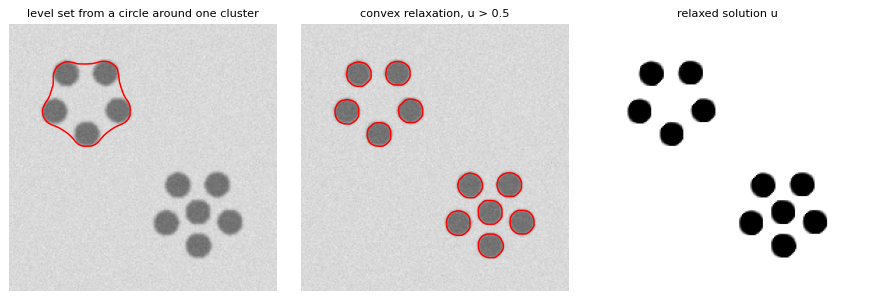

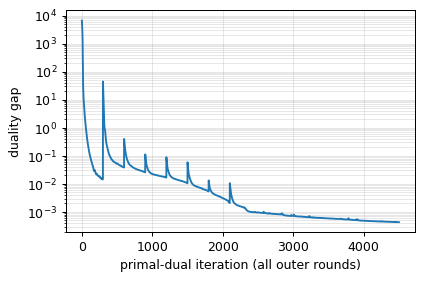

In [51]:
mu_b = 0.3
yy_d, xx_d = np.mgrid[0:disks.shape[0], 0:disks.shape[1]]
phi_bad = 30.0 - np.sqrt((xx_d - 55.0) ** 2 + (yy_d - 55.0) ** 2)      # signed distance to a circle around ONE cluster

t0 = time.time()
phi_ls, its_ls, _ = chan_vese(disks, mu=mu_b, phi0=phi_bad, max_iter=3000)
t_ls = time.time() - t0
t0 = time.time()
u_cx, c_cx, gaps_cx = chan_vese_convex(disks, mu_b)
t_cx = time.time() - t0

segs_b = {"level set, circle init.": phi_ls >= 0,
          "level set, checkerboard": mu_phis[mus.index(mu_b)] >= 0,
          "convex relaxation": u_cx > 0.5}
energy_b = {k: binary_energy(disks, s, mu_b) for k, s in segs_b.items()}
comps_b = {k: ndi.label(s if disks[s].mean() < disks[~s].mean() else ~s)[1] for k, s in segs_b.items()}
for k in segs_b:
    print(f"{k:>24}: energy {energy_b[k]:8.2f}, {comps_b[k]} dark components")
print(f"times: level set {t_ls:.1f} s ({its_ls} it.), convex {t_cx:.1f} s;  fraction of u strictly inside (0.01, 0.99): "
      f"{np.mean((u_cx > 0.01) & (u_cx < 0.99)):.3f}")
show([disks, disks, u_cx], ["level set from a circle around one cluster", "convex relaxation, u > 0.5", "relaxed solution u"],
     contours=[phi_ls, u_cx - 0.5, None])
plt.figure(figsize=(5, 3.2)); plt.semilogy(gaps_cx); plt.xlabel("primal-dual iteration (all outer rounds)")
plt.ylabel("duality gap"); plt.grid(alpha=0.3, which="both"); plt.show()

<div style="background-color:#e6f4ea; border-left:6px solid #34a853; padding:6px 12px; font-weight:bold; color:#1e4620;">🟩 Question QB.1 (0.4 bonus points) — answer in the green cell below</div>

**QB.1** *(0.4 bonus points).* Report the energies and the numbers of dark components of the three segmentations. Which one is the lowest, and why can the level set started from the circle not reach it?

In [61]:
# 🟩🟩🟩 ANSWER CELL — QB.1 🟩🟩🟩
answer("QB.1", "1: 375.99, 1 dark components; 2: 257.06, 11 dark components; 3: 246.15, 11 dark components. The solution that obtains the lowest energy is the convex relaxation, as it is able to find and segment the 11 dark disks on the image. On the other hand, the level set that starts from a circle is not able to separate all of the disks, instead it only finds one cluster that surrounds 5 of said points. This occurs becouse of the non-convexity of the problem; the gradient descent is only able to find a solution that is near to the starting position, therefore stays stuck at a local minimum.")

<div style="background-color:#e6f4ea; border-left:6px solid #34a853; padding:6px 12px; font-weight:bold; color:#1e4620;">🟩 Question QB.2 (0.3 bonus points) — answer in the green cell below</div>

**QB.2** *(0.3 bonus points).* Report the first and the last value of the duality gap. What does the final value guarantee about the last relaxed solution (for the last $c_1,c_2$)? Why does the gap jump up at the beginning of each outer round?

In [64]:
# 🟩🟩🟩 ANSWER CELL — QB.2 🟩🟩🟩
answer("QB.2", f"first gap = {gaps_cx[0]:.1f}, last gap = {gaps_cx[-1]:.1e}."
  "By weak duality, D(p) <= min P <= P(u), so the final gap bounds P(u) - P(u*): the last relaxed solution is optimal for the "
  "last (c1, c2) up to ~1e-3 in energy, out of about 230 (relative error ~1e-6). The gap jumps up at the start of each outer "
  "round because c1, c2 are updated, so the region cost r changes: the warm-started (u, p) was optimal for "
  "the old r and is no longer for the new problem, so P(u) - D(p) is large again and then decays as the iterations re-converge.")

  isotropic TV: relaxed energy   228.661;  thresholded at t = 0.25 / 0.5 / 0.75: 249.722 / 246.152 / 245.812;  fraction of fractional pixels 0.0205
anisotropic TV: relaxed energy   255.724;  thresholded at t = 0.25 / 0.5 / 0.75: 255.724 / 255.724 / 255.724;  fraction of fractional pixels 0.0000


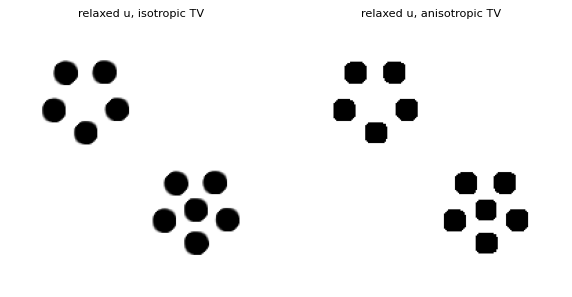

In [65]:
u_an, c_an, gaps_an = chan_vese_convex(disks, mu_b, iso=False)
thr_table = {}
for name, u_, (c1_, c2_), iso in [("isotropic", u_cx, c_cx, True), ("anisotropic", u_an, c_an, False)]:
    data_const = float(np.sum((disks - c2_) ** 2))
    relaxed = mu_b * tv(u_, iso) + float(np.sum(((disks - c1_) ** 2 - (disks - c2_) ** 2) * u_)) + data_const
    energies_t = {t: binary_energy(disks, u_ > t, mu_b, c=(c1_, c2_), iso=iso) for t in [0.25, 0.5, 0.75]}
    thr_table[name] = (relaxed, energies_t, float(np.mean((u_ > 0.01) & (u_ < 0.99))))
    print(f"{name:>11} TV: relaxed energy {relaxed:9.3f};  thresholded at t = 0.25 / 0.5 / 0.75: "
          + " / ".join(f"{e:.3f}" for e in energies_t.values())
          + f";  fraction of fractional pixels {thr_table[name][2]:.4f}")
show([u_cx, u_an], ["relaxed u, isotropic TV", "relaxed u, anisotropic TV"])

<div style="background-color:#e6f4ea; border-left:6px solid #34a853; padding:6px 12px; font-weight:bold; color:#1e4620;">🟩 Question QB.3 (0.3 bonus points) — answer in the green cell below</div>

**QB.3** *(0.3 bonus points).* For both discrete TVs, report the relaxed energy $E(u^\ast)$ and the binary energies obtained by thresholding $u^\ast$ at $t=0.25,0.5,0.75$ (with fixed $c_1,c_2$). For which TV does the thresholding theorem of Step 3 hold exactly, and why? What is the price of the anisotropic TV in terms of the shape of the boundaries (look at the relaxed solutions)?

In [67]:
# 🟩🟩🟩 ANSWER CELL — QB.3 🟩🟩🟩
answer("QB.3", "; ".join(f"{n}: relaxed E = {v[0]:.3f}, thresholded t=0.25/0.5/0.75: "
  + " / ".join(f'{e:.3f}' for e in v[1].values()) + f", fractional pixels {v[2]:.3f}"
  for n, v in thr_table.items()) +
  "The relaxed solution is already binary, the three thresholded energies coincide with the relaxed one. For the isotropic TV they are not equal: the "
  "relaxed energy is lower than all thresholded ones, because the discrete coarea formula is only approximate."
  "The anisotropic TV measureslength in the l1 norm |d_i u| + |d_j u|, so horizontal/vertical edges are cheap and oblique ones are "
  "more expensive: the boundaries become blocky and grid-aligned, and the disks come out as squares instead of round.")

---
## Grading table

| question | topic | points | score |
|---|---|---|---|
| Q1.1 | 1D, gamma = 0 vs thresholding | 0.5 | |
| Q1.2 | 1D, effect of gamma | 0.5 | |
| Q1.3 | 1D, level-set count of jumps | 0.5 | |
| Q2.1 | length through delta_eps | 0.5 | |
| Q2.2 | energy symmetry and the area term | 0.5 | |
| Q3.1 | explicit vs semi-implicit stability | 0.5 | |
| Q3.2 | checkerboard vs circle initialization | 0.5 | |
| Q3.3 | role of delta_eps | 0.5 | |
| Q4.1 | phantom2: Chan-Vese vs Otsu | 0.5 | |
| Q4.2 | accuracy vs noise level | 0.5 | |
| Q4.3 | effect of mu | 0.5 | |
| Q5.1 | equal lambdas on phantom3 | 0.5 | |
| Q5.2 | unequal lambdas without area term | 0.5 | |
| Q5.3 | the threshold tau | 0.5 | |
| Q5.4 | Gaussian interpretation and sensitivity to nu | 0.5 | |
| Q5.5 | adaptive variances and initialization | 0.5 | |
| Q6.1 | color phantom and change of color basis | 1 | |
| Q6.2 | your own image | 1 | |
| QB.1 | convex vs level set: energies (bonus) | 0.4 | |
| QB.2 | duality gap (bonus) | 0.3 | |
| QB.3 | thresholding theorem (bonus) | 0.3 | |
| **total** | | **10** (+1 bonus) | |

---
**End of the lab.** Run `Runtime → Restart session and run all`, check that every green box shows an answer, and download the notebook with all outputs.